# COMS4060A/7056A Assignment 2: NYC Taxi Trips

This notebook covers Question 1 (Data Cleaning), Question 2 (Feature Generation), Question 3 (Time-based analysis),
Question 4 (Location clusters: heatmaps and DBSCAN hotspots) and Question 5 (Airports).
Every figure is saved as a PNG in the current directory, named after the question it belongs to
(for example `q3_1_trips_by_weekday.png`), so that it can be included in the LaTeX report.

The notebook expects `train.csv` (the Kaggle training file) in the same folder.

Questions 4 and 5 also need `scikit-learn`, `scipy` and `folium` (`pip install scikit-learn scipy folium`). They save PNG figures plus two interactive maps (`q4_1_heatmaps.html`, `q4_2_hotspots.html`).

In [4]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#2a78d6", "#0d366b"])

mpl.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 200,
    "savefig.bbox": "tight", "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "text.color": INK,
})

DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def save(fig, name):
    fig.savefig(name)
    plt.show()
    print("saved", name)


def haversine_np(lon1, lat1, lon2, lat2):
    # Great circle distance in km between points given in decimal degrees (from the assignment brief).
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6367 * c

# Question 1: Data Cleaning

In [5]:
df = pd.read_csv("train.csv", parse_dates=["pickup_datetime", "dropoff_datetime"])
print("shape:", df.shape)
display(df.head())
print(df.dtypes)
print("missing values:", int(df.isna().sum().sum()))
print("duplicate ids:", int(df.id.duplicated().sum()))
dur_check = (df.dropoff_datetime - df.pickup_datetime).dt.total_seconds()
print("rows where trip_duration differs from dropoff minus pickup:", int((dur_check != df.trip_duration).sum()))
print("pickup range:", df.pickup_datetime.min(), "to", df.pickup_datetime.max())

shape: (1458644, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


id                               str
vendor_id                      int64
pickup_datetime       datetime64[us]
dropoff_datetime      datetime64[us]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag               str
trip_duration                  int64
dtype: object
missing values: 0
duplicate ids: 0
rows where trip_duration differs from dropoff minus pickup: 0
pickup range: 2016-01-01 00:00:17 to 2016-06-30 23:59:39


Distance and speed are needed to find outliers, so we compute them first (Question 2 allows feature generation before or after cleaning).
Distance is the straight line (haversine) distance between pickup and dropoff, so it is a lower bound on the real road distance.

In [6]:
df["distance_km"] = haversine_np(df.pickup_longitude, df.pickup_latitude,
                                 df.dropoff_longitude, df.dropoff_latitude)
df["avg_speed_kmh"] = df.distance_km / (df.trip_duration / 3600)

raw = df[["trip_duration", "distance_km", "avg_speed_kmh", "passenger_count"]]
display(raw.describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T)
print("passenger_count values:")
print(df.passenger_count.value_counts().sort_index())

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
trip_duration,1458644.0,959.492273,5237.431724,1.0,7.0,87.000000,662.000000,3440.000000,85128.357000,3.526282e+06
distance_km,1458644.0,3.438704,4.293840,0.0,0.0,0.138935,2.092403,20.774468,24.751208,1.240130e+03
avg_speed_kmh,1458644.0,14.414153,14.968121,0.0,0.0,1.393366,12.783947,40.719722,54.267879,9.269014e+03
passenger_count,1458644.0,1.664530,1.314242,0.0,1.0,1.000000,1.000000,6.000000,6.000000,9.000000e+00


passenger_count values:
passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64


## Outlier rules

Each rule below has a physical or practical reason, and the table after it shows how many trips each rule flags.

| Rule | Reason |
|---|---|
| Pickup or dropoff outside the NYC area (lon -74.3 to -73.65, lat 40.45 to 41.0) | The data is for NYC taxis. Points in other states, the ocean or at (0, 0) are GPS errors. The box still contains JFK, LaGuardia and Newark. |
| Passenger count 0 or above 6 | A taxi with no passenger is not a fare, and vehicles used as taxis seat at most 6 people, so counts of 7 to 9 are entry errors (the count is typed in by the driver). |
| Duration under 60 s | Too short for a real fare. Mostly cancelled rides or a meter switched on by mistake. |
| Duration over 3 hours | Almost no legitimate trip inside NYC takes this long. There is a clear spike of trips close to 24 hours, which is a meter left running. |
| Distance under 50 m | The pickup and dropoff are at the same place, so the speed is meaningless. These are cancelled trips. |
| Speed over 100 km/h | The speed is measured in a straight line, so real speed is even higher. This is faster than the fastest legal road speed around NYC. |
| Speed under 1 km/h | Slower than walking, so the car effectively did not move for the whole trip. |

In [7]:
LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = -74.3, -73.65, 40.45, 41.0
MIN_DUR, MAX_DUR = 60, 3 * 3600
MIN_DIST = 0.05
MIN_SPEED, MAX_SPEED = 1, 100

inside = (df.pickup_longitude.between(LON_MIN, LON_MAX) & df.pickup_latitude.between(LAT_MIN, LAT_MAX) &
          df.dropoff_longitude.between(LON_MIN, LON_MAX) & df.dropoff_latitude.between(LAT_MIN, LAT_MAX))

rules = {
    "Pickup or dropoff outside NYC area": ~inside,
    "Passenger count 0 or above 6": ~df.passenger_count.between(1, 6),
    "Duration under 60 s": df.trip_duration < MIN_DUR,
    "Duration over 3 hours": df.trip_duration > MAX_DUR,
    "Distance under 50 m": df.distance_km < MIN_DIST,
    "Speed over 100 km/h": df.avg_speed_kmh > MAX_SPEED,
    "Speed under 1 km/h": df.avg_speed_kmh < MIN_SPEED,
}

keep = pd.Series(True, index=df.index)
rows = []
for name, mask in rules.items():
    newly = int((mask & keep).sum())
    keep &= ~mask
    rows.append({"rule": name, "flagged_alone": int(mask.sum()), "newly_removed": newly,
                 "cumulative_removed": int((~keep).sum())})
removal = pd.DataFrame(rows)
removal["flagged_alone_%"] = (removal.flagged_alone / len(df) * 100).round(3)
removal["newly_removed_%"] = (removal.newly_removed / len(df) * 100).round(3)
display(removal)

df_raw = df
df = df_raw[keep].copy()
print("rows before:", len(df_raw), " rows after:", len(df),
      " removed:", len(df_raw) - len(df), f"({(1 - len(df) / len(df_raw)) * 100:.2f}%)")
display(df[["trip_duration", "distance_km", "avg_speed_kmh", "passenger_count"]]
        .describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T)

,rule,flagged_alone,newly_removed,cumulative_removed,flagged_alone_%,newly_removed_%
0,Pickup or dropoff outside NYC area,773,773,773,0.053,0.053
1,Passenger count 0 or above 6,65,64,837,0.004,0.004
2,Duration under 60 s,8595,8434,9271,0.589,0.578
3,Duration over 3 hours,2112,2105,11376,0.145,0.144
4,Distance under 50 m,11333,6155,17531,0.777,0.422
5,Speed over 100 km/h,175,33,17564,0.012,0.002
6,Speed under 1 km/h,13241,2050,19614,0.908,0.141


rows before: 1458644  rows after: 1439030  removed: 19614 (1.34%)


,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
trip_duration,1439030.0,840.451272,653.528781,60.000000,69.000000,111.000000,665.000000,3303.000000,5046.000000,10731.00000
distance_km,1439030.0,3.459864,3.889074,0.050192,0.153794,0.382198,2.116495,20.743383,23.706265,47.73514
avg_speed_kmh,1439030.0,14.466055,7.596428,1.000377,1.539719,3.313453,12.850014,40.374586,52.431961,99.46905
passenger_count,1439030.0,1.665054,1.314261,1.000000,1.000000,1.000000,1.000000,6.000000,6.000000,6.00000


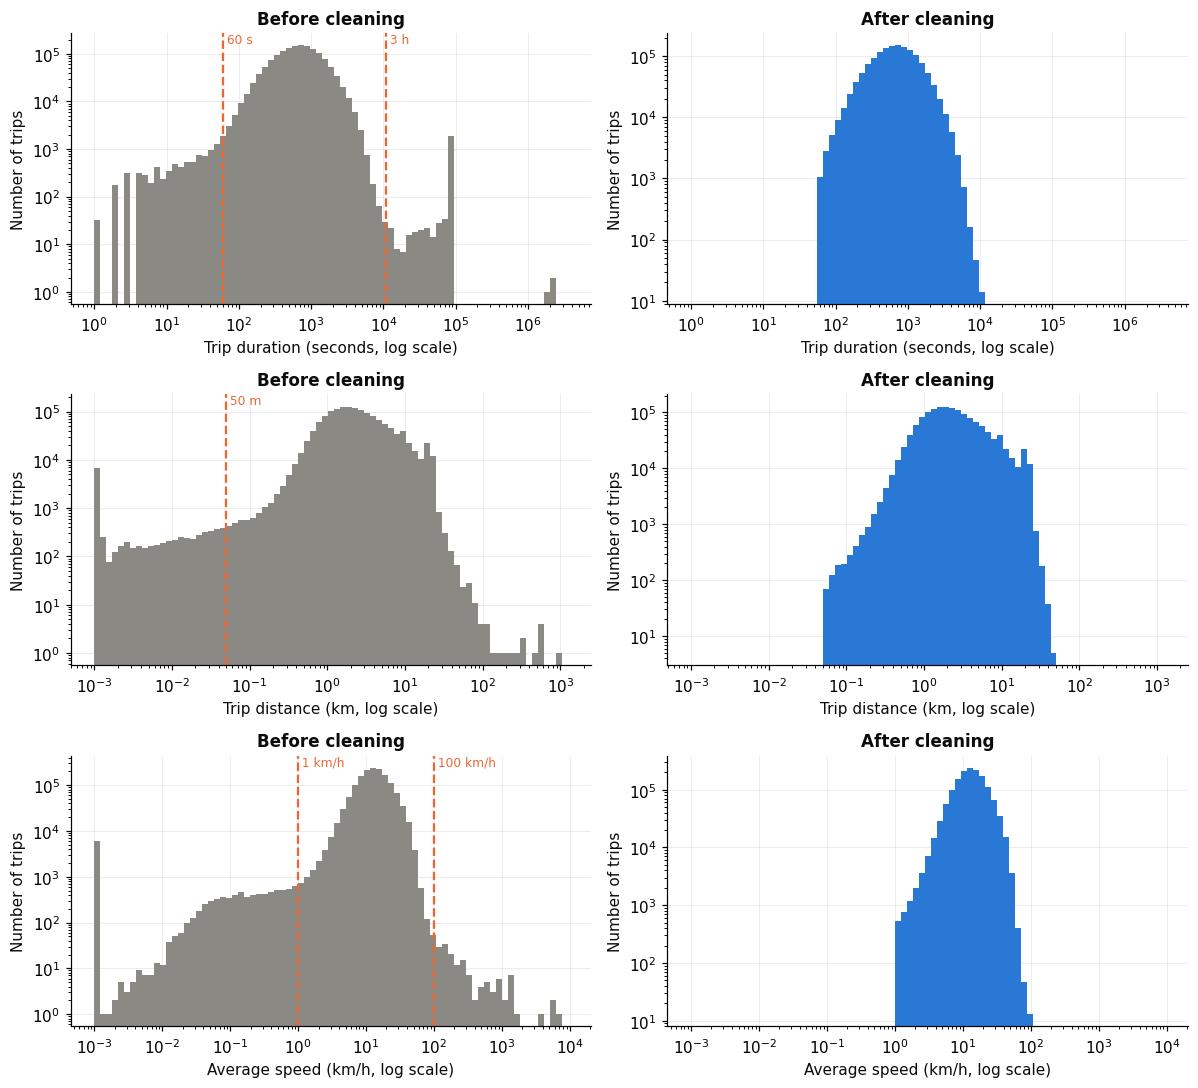

saved q1_outliers_before_after.png


In [8]:
def logbins(x, n=80):
    x = x[x > 0]
    return np.logspace(np.log10(x.min()), np.log10(x.max()), n)

fig, axes = plt.subplots(3, 2, figsize=(11, 10))
specs = [
    ("trip_duration", "Trip duration (seconds, log scale)", [(MIN_DUR, "60 s"), (MAX_DUR, "3 h")]),
    ("distance_km", "Trip distance (km, log scale)", [(MIN_DIST, "50 m")]),
    ("avg_speed_kmh", "Average speed (km/h, log scale)", [(MIN_SPEED, "1 km/h"), (MAX_SPEED, "100 km/h")]),
]
for i, (col, label, lines) in enumerate(specs):
    bins = logbins(df_raw[col].clip(lower=1e-3))
    for j, (data, title, colour) in enumerate([(df_raw, "Before cleaning", GREY), (df, "After cleaning", BLUE)]):
        ax = axes[i, j]
        ax.hist(data[col].clip(lower=1e-3), bins=bins, color=colour)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(label)
        ax.set_ylabel("Number of trips")
        ax.set_title(title)
        if j == 0:
            for v, t in lines:
                ax.axvline(v, color=ORANGE, lw=1.5, ls="--")
                ax.text(v, ax.get_ylim()[1], " " + t, color=ORANGE, va="top", ha="left", fontsize=8)
fig.tight_layout()
save(fig, "q1_outliers_before_after.png")

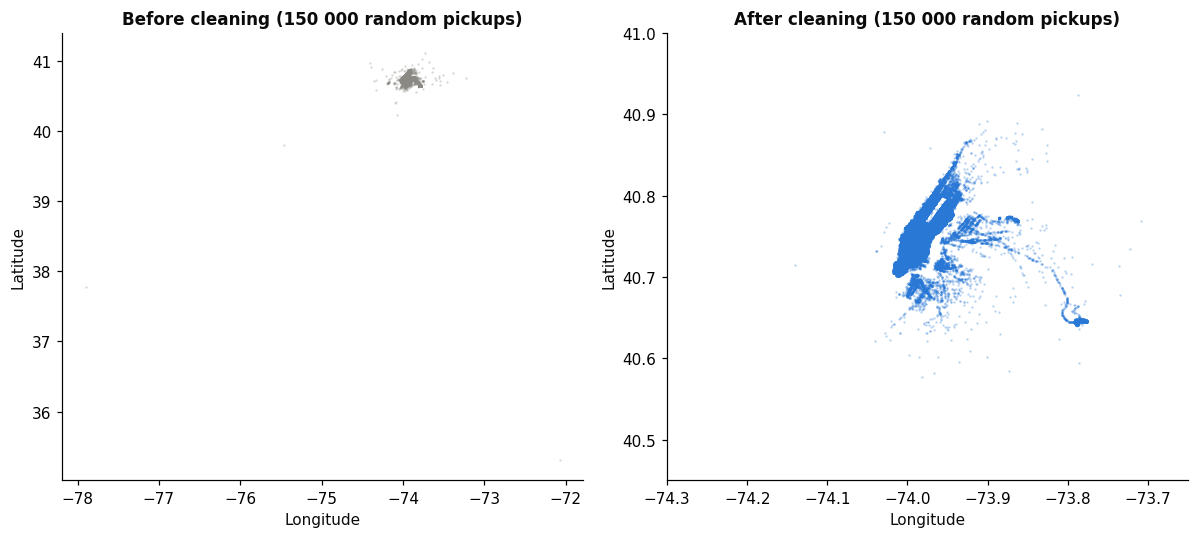

saved q1_pickup_coordinates_before_after.png


In [9]:
samp_raw = df_raw.sample(150000, random_state=42)
samp_clean = df.sample(150000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, data, title, colour in [(axes[0], samp_raw, "Before cleaning", GREY), (axes[1], samp_clean, "After cleaning", BLUE)]:
    ax.scatter(data.pickup_longitude, data.pickup_latitude, s=0.3, alpha=0.3, color=colour, rasterized=True)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title + " (150 000 random pickups)")
    ax.grid(False)
axes[1].set_xlim(LON_MIN, LON_MAX)
axes[1].set_ylim(LAT_MIN, LAT_MAX)
fig.tight_layout()
save(fig, "q1_pickup_coordinates_before_after.png")

# Question 2: Feature Generation

Distance and average speed were already created in Question 1 (they are needed to find outliers).
Here we confirm them on the cleaned data and add the day of week and a few helper columns that the later questions use.

In [10]:
dt = df.pickup_datetime.dt
df["day_of_week"] = dt.day_name()
df["dow"] = dt.dayofweek                 # 0 = Monday, 6 = Sunday
df["is_weekend"] = df.dow >= 5
df["day_type"] = np.where(df.is_weekend, "Weekend", "Weekday")
df["hour"] = dt.hour
df["date"] = dt.normalize()
df["month"] = dt.month
df["duration_min"] = df.trip_duration / 60

# distance_km uses the haversine formula and avg_speed_kmh = distance_km / (trip_duration / 3600)
check = (df.distance_km / (df.trip_duration / 3600) - df.avg_speed_kmh).abs().max()
print("largest difference when recomputing speed:", check)

new_cols = ["pickup_datetime", "trip_duration", "distance_km", "day_of_week", "hour", "is_weekend", "avg_speed_kmh"]
display(df[new_cols].head(8))
display(df[["distance_km", "duration_min", "avg_speed_kmh"]].describe().T)

largest difference when recomputing speed: 0.0


,pickup_datetime,trip_duration,distance_km,day_of_week,hour,is_weekend,avg_speed_kmh
0,2016-03-14 17:24:55,455,1.497580,Monday,17,False,11.848984
1,2016-06-12 00:43:35,663,1.804374,Sunday,0,True,9.797504
2,2016-01-19 11:35:24,2124,6.381090,Tuesday,11,False,10.815406
3,2016-04-06 19:32:31,429,1.484566,Wednesday,19,False,12.457894
4,2016-03-26 13:30:55,435,1.187842,Saturday,13,True,9.830418
5,2016-01-30 22:01:40,443,1.098252,Saturday,22,True,8.924851
6,2016-06-17 22:34:59,341,1.325446,Friday,22,False,13.992977
7,2016-05-21 07:54:58,1551,5.711393,Saturday,7,True,13.256617


,count,mean,std,min,25%,50%,75%,max
distance_km,1439030.0,3.459864,3.889074,0.050192,1.255905,2.116495,3.904652,47.73514
duration_min,1439030.0,14.007521,10.892146,1.000000,6.683333,11.083333,17.916667,178.85000
avg_speed_kmh,1439030.0,14.466055,7.596428,1.000377,9.224819,12.850014,17.870927,99.46905


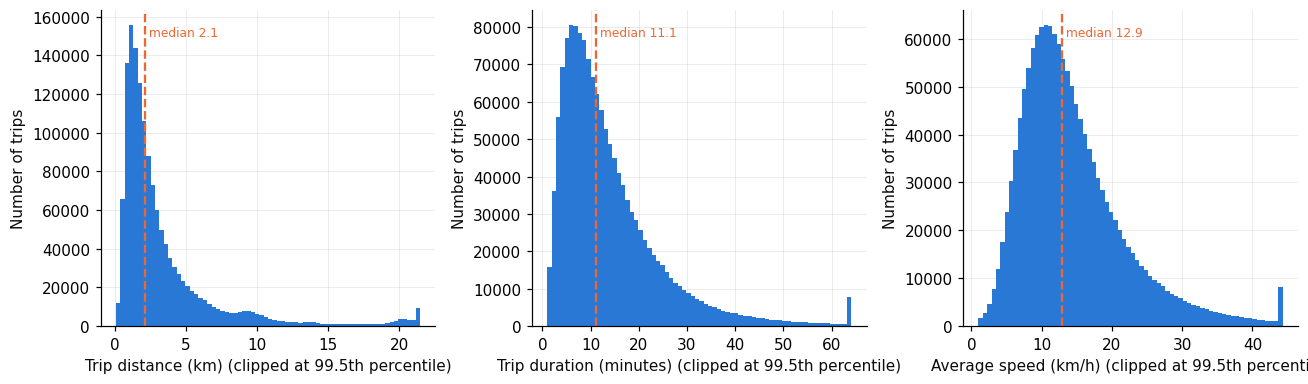

saved q2_feature_distributions.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col, label, hi in [(axes[0], "distance_km", "Trip distance (km)", None),
                           (axes[1], "duration_min", "Trip duration (minutes)", None),
                           (axes[2], "avg_speed_kmh", "Average speed (km/h)", None)]:
    upper = df[col].quantile(0.995)
    ax.hist(df[col].clip(upper=upper), bins=70, color=BLUE)
    ax.axvline(df[col].median(), color=ORANGE, lw=1.5, ls="--")
    ax.text(df[col].median(), ax.get_ylim()[1] * 0.95, f" median {df[col].median():.1f}", color=ORANGE, va="top", fontsize=8)
    ax.set_xlabel(label + " (clipped at 99.5th percentile)")
    ax.set_ylabel("Number of trips")
fig.tight_layout()
save(fig, "q2_feature_distributions.png")

# Question 3: Time-based analysis

Pickup time is used throughout. The data covers 2016-01-01 to 2016-06-30, which is exactly 26 weeks,
so every day of the week occurs exactly 26 times and the totals per day of the week can be compared fairly.

## 3.1 Most popular day of the week

In [12]:
daily = df.groupby("date").size().rename("trips").to_frame()
daily["day_of_week"] = daily.index.day_name()
n_days = daily.groupby("day_of_week").size().reindex(DAYS)
by_day = df.groupby("day_of_week").size().reindex(DAYS)

summary = pd.DataFrame({
    "trips": by_day,
    "share_%": (by_day / by_day.sum() * 100).round(2),
    "days_in_data": n_days,
    "mean_trips_per_day": (by_day / n_days).round(0),
    "median_trips_per_day": daily.groupby("day_of_week").trips.median().reindex(DAYS).round(0),
})
# 23 and 24 January 2016 was a blizzard that shut the city down, so we also look at the days without it
blizzard_days = [pd.Timestamp("2016-01-23"), pd.Timestamp("2016-01-24")]
daily_nb = daily.drop(blizzard_days)
summary["mean_trips_per_day_no_blizzard"] = daily_nb.groupby("day_of_week").trips.mean().reindex(DAYS).round(0)
display(summary)
print("Most popular day by total trips:", by_day.idxmax())
print("Most popular day by median daily trips:", summary.median_trips_per_day.idxmax())
print("Most popular day by mean daily trips without the blizzard days:", summary.mean_trips_per_day_no_blizzard.idxmax())
print()
print("Ten quietest days:")
display(daily.sort_values("trips").head(10))

,trips,share_%,days_in_data,mean_trips_per_day,median_trips_per_day,mean_trips_per_day_no_blizzard
day_of_week,,,,,,
Monday,184917,12.85,26,7112.0,7174.0,7112.0
Tuesday,200072,13.90,26,7695.0,7710.0,7695.0
Wednesday,207492,14.42,26,7980.0,7941.0,7980.0
Thursday,215636,14.98,26,8294.0,8310.0,8294.0
Friday,220506,15.32,26,8481.0,8570.0,8481.0
Saturday,217882,15.14,26,8380.0,8797.0,8651.0
Sunday,192525,13.38,26,7405.0,7640.0,7568.0


Most popular day by total trips: Friday
Most popular day by median daily trips: Saturday
Most popular day by mean daily trips without the blizzard days: Saturday

Ten quietest days:


,trips,day_of_week
date,,
2016-01-23,1615,Saturday
2016-01-24,3322,Sunday
2016-05-30,5491,Monday
2016-01-25,5976,Monday
2016-01-03,6241,Sunday
2016-05-29,6281,Sunday
2016-01-02,6424,Saturday
2016-01-04,6614,Monday
2016-06-20,6806,Monday


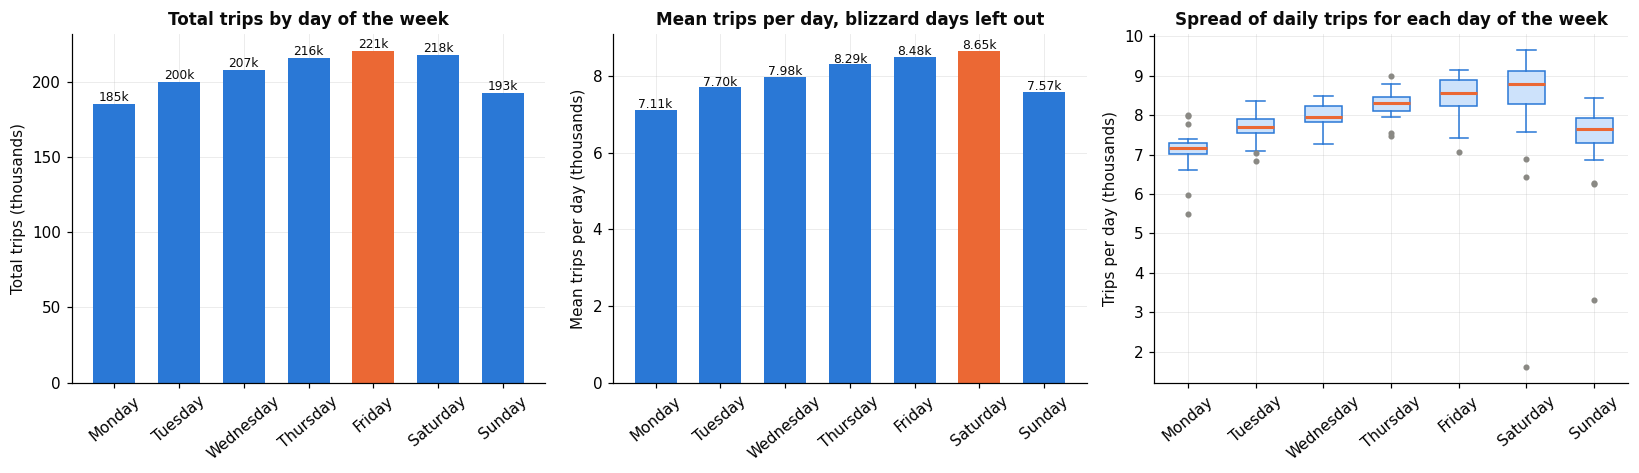

saved q3_1_trips_by_weekday.png


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]
colours = [ORANGE if d == by_day.idxmax() else BLUE for d in DAYS]
ax.bar(DAYS, by_day / 1000, color=colours, width=0.65)
for i, v in enumerate(by_day / 1000):
    ax.text(i, v + 2, f"{v:.0f}k", ha="center", fontsize=8)
ax.set_ylabel("Total trips (thousands)")
ax.set_title("Total trips by day of the week")
ax.tick_params(axis="x", rotation=40)

ax = axes[1]
m = summary.mean_trips_per_day_no_blizzard
colours = [ORANGE if d == m.idxmax() else BLUE for d in DAYS]
ax.bar(DAYS, m / 1000, color=colours, width=0.65)
for i, v in enumerate(m / 1000):
    ax.text(i, v + 0.05, f"{v:.2f}k", ha="center", fontsize=8)
ax.set_ylabel("Mean trips per day (thousands)")
ax.set_title("Mean trips per day, blizzard days left out")
ax.tick_params(axis="x", rotation=40)

ax = axes[2]
data = [daily[daily.day_of_week == d].trips.values / 1000 for d in DAYS]
ax.boxplot(data, tick_labels=DAYS, widths=0.55, patch_artist=True, showfliers=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=ORANGE, lw=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GREY, markeredgecolor=GREY))
ax.set_ylabel("Trips per day (thousands)")
ax.set_title("Spread of daily trips for each day of the week")
ax.tick_params(axis="x", rotation=40)
fig.tight_layout()
save(fig, "q3_1_trips_by_weekday.png")

## 3.2 Most popular hour on each day

In [14]:
hourly = df.groupby(["day_of_week", "hour"]).size().unstack("hour").reindex(DAYS)
peak = pd.DataFrame({
    "peak_hour": hourly.idxmax(axis=1),
    "trips_at_peak": hourly.max(axis=1),
    "quietest_hour": hourly.idxmin(axis=1),
    "trips_at_quietest": hourly.min(axis=1),
})
display(peak)
overall_hour = df.groupby("hour").size()
print("Overall peak hour:", overall_hour.idxmax(), " overall quietest hour:", overall_hour.idxmin())
print()
print("Share of trips between 18:00 and 19:59 on each day (%):")
print((hourly.loc[:, 18:19].sum(axis=1) / hourly.sum(axis=1) * 100).round(1))

,peak_hour,trips_at_peak,quietest_hour,trips_at_quietest
day_of_week,,,,
Monday,18,12812,3,1204
Tuesday,18,13315,3,989
Wednesday,19,13549,4,1223
Thursday,21,13986,4,1348
Friday,19,13998,4,2261
Saturday,23,13030,5,1954
Sunday,0,12116,5,1912


Overall peak hour: 18  overall quietest hour: 5

Share of trips between 18:00 and 19:59 on each day (%):
day_of_week
Monday       13.5
Tuesday      13.1
Wednesday    12.8
Thursday     12.7
Friday       12.4
Saturday     11.8
Sunday       10.9
dtype: float64


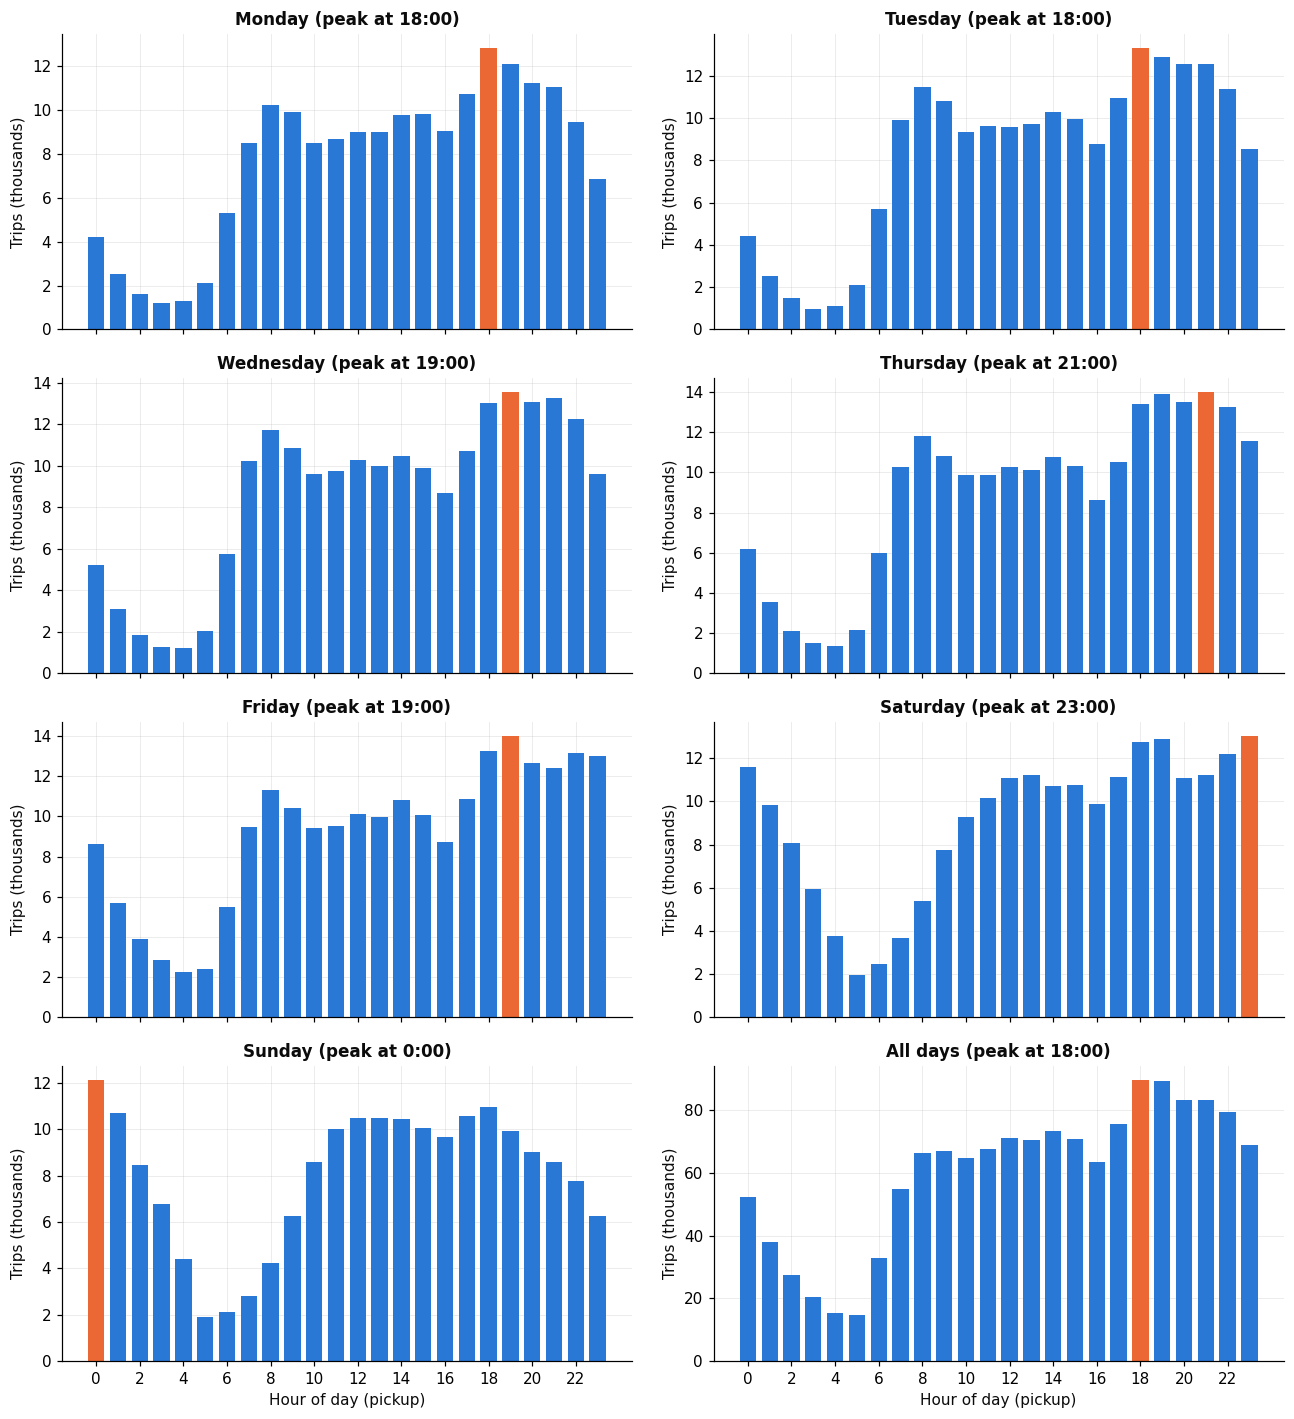

saved q3_2_hourly_by_day.png


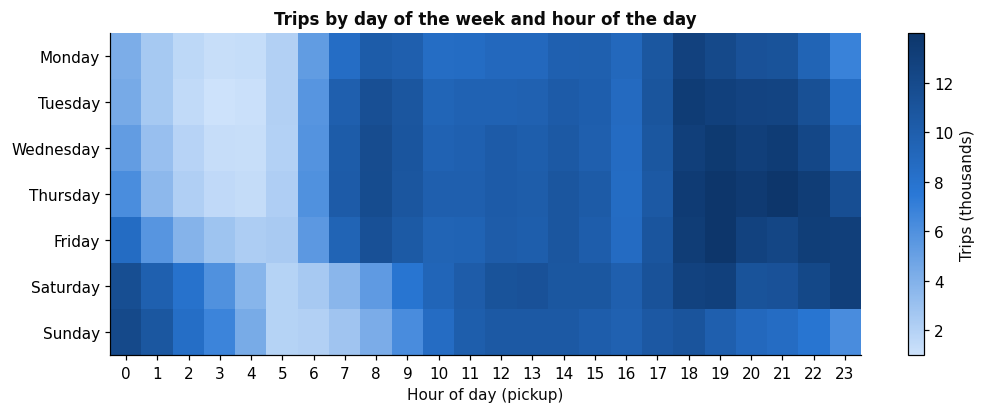

saved q3_2_heatmap_day_hour.png


In [15]:
fig, axes = plt.subplots(4, 2, figsize=(12, 13), sharex=True)
panels = DAYS + ["All days"]
for ax, name in zip(axes.ravel(), panels):
    vals = (overall_hour if name == "All days" else hourly.loc[name]) / 1000
    colours = [ORANGE if h == vals.idxmax() else BLUE for h in vals.index]
    ax.bar(vals.index, vals.values, color=colours, width=0.75)
    ax.set_title(f"{name} (peak at {vals.idxmax()}:00)")
    ax.set_ylabel("Trips (thousands)")
for ax in axes[-1]:
    ax.set_xlabel("Hour of day (pickup)")
    ax.set_xticks(range(0, 24, 2))
fig.tight_layout()
save(fig, "q3_2_hourly_by_day.png")

fig, ax = plt.subplots(figsize=(11, 3.8))
M = hourly.values / 1000
im = ax.imshow(M, aspect="auto", cmap=SEQ)
ax.set_xticks(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(DAYS)
ax.set_xlabel("Hour of day (pickup)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax)
cb.set_label("Trips (thousands)")
ax.set_title("Trips by day of the week and hour of the day")
save(fig, "q3_2_heatmap_day_hour.png")

## 3.3 Weekdays versus weekends

In [16]:
days_per_type = daily.assign(day_type=np.where(daily.index.dayofweek >= 5, "Weekend", "Weekday")).groupby("day_type").size()
trips_per_type = df.groupby("day_type").size()
print("days in data:", days_per_type.to_dict())
print("mean trips per day:", (trips_per_type / days_per_type).round(0).to_dict())

profile = df.groupby(["hour", "day_type"]).size().unstack("day_type")
profile_share = profile / profile.sum() * 100
profile_abs = profile / days_per_type

stats = df.groupby("day_type").agg(
    mean_distance_km=("distance_km", "mean"),
    median_distance_km=("distance_km", "median"),
    mean_duration_min=("duration_min", "mean"),
    mean_speed_kmh=("avg_speed_kmh", "mean"),
    mean_passengers=("passenger_count", "mean"),
).round(2)
stats["share_multi_passenger_%"] = (df.assign(m=df.passenger_count > 1).groupby("day_type").m.mean() * 100).round(1)
stats["share_midnight_to_5am_%"] = (df.assign(n=df.hour < 5).groupby("day_type").n.mean() * 100).round(1)
stats["share_7am_to_10am_%"] = (df.assign(n=df.hour.between(7, 9)).groupby("day_type").n.mean() * 100).round(1)
display(stats)
print("Peak hour weekday:", profile_share.Weekday.idxmax(), " weekend:", profile_share.Weekend.idxmax())

days in data: {'Weekday': 130, 'Weekend': 52}
mean trips per day: {'Weekday': 7912.0, 'Weekend': 7892.0}


,mean_distance_km,median_distance_km,mean_duration_min,mean_speed_kmh,mean_passengers,share_multi_passenger_%,share_midnight_to_5am_%,share_7am_to_10am_%
day_type,,,,,,,,
Weekday,3.43,2.07,14.45,13.92,1.64,27.7,7.0,15.3
Weekend,3.54,2.23,12.91,15.84,1.72,32.8,19.9,7.3


Peak hour weekday: 19  weekend: 0


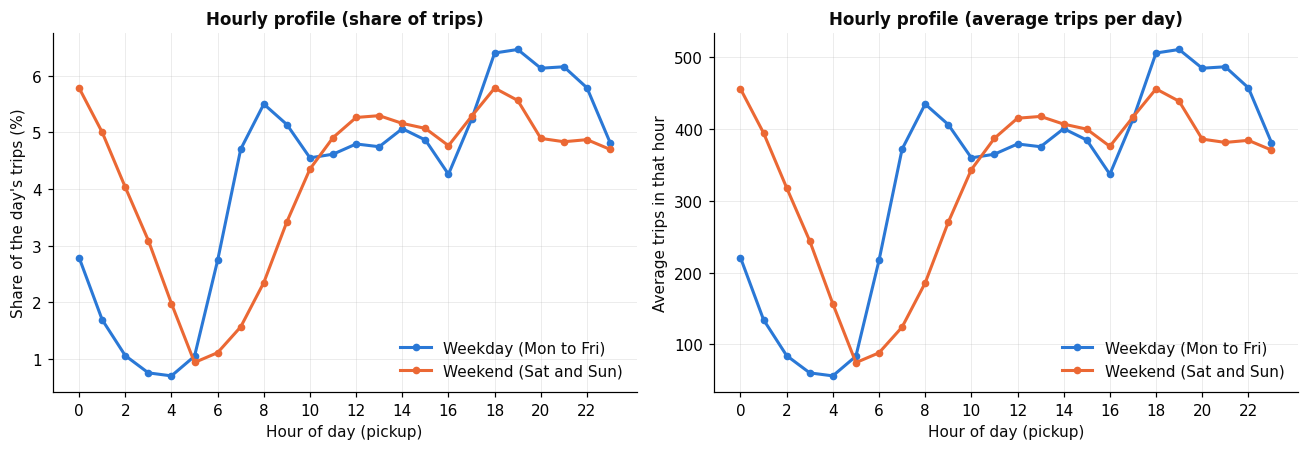

saved q3_3_weekday_vs_weekend_hourly.png


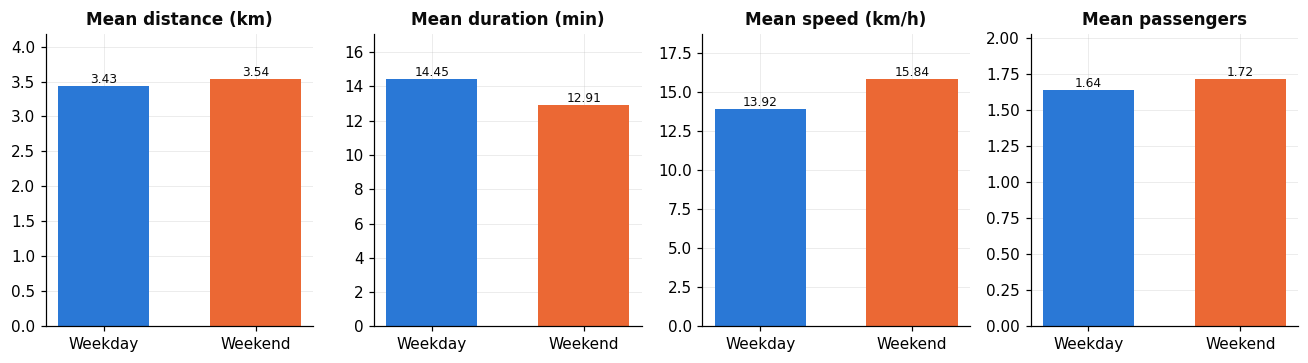

saved q3_3_weekday_weekend_stats.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, data, ylabel, title in [
    (axes[0], profile_share, "Share of the day's trips (%)", "Hourly profile (share of trips)"),
    (axes[1], profile_abs, "Average trips in that hour", "Hourly profile (average trips per day)"),
]:
    ax.plot(data.index, data.Weekday, color=BLUE, lw=2, marker="o", ms=4, label="Weekday (Mon to Fri)")
    ax.plot(data.index, data.Weekend, color=ORANGE, lw=2, marker="o", ms=4, label="Weekend (Sat and Sun)")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hour of day (pickup)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False)
fig.tight_layout()
save(fig, "q3_3_weekday_vs_weekend_hourly.png")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, col, label in [(axes[0], "mean_distance_km", "Mean distance (km)"),
                       (axes[1], "mean_duration_min", "Mean duration (min)"),
                       (axes[2], "mean_speed_kmh", "Mean speed (km/h)"),
                       (axes[3], "mean_passengers", "Mean passengers")]:
    v = stats.loc[["Weekday", "Weekend"], col]
    ax.bar(v.index, v.values, color=[BLUE, ORANGE], width=0.6)
    for i, x in enumerate(v.values):
        ax.text(i, x, f"{x:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(label)
    ax.set_ylim(0, v.max() * 1.18)
fig.tight_layout()
save(fig, "q3_3_weekday_weekend_stats.png")

## 3.4 Major holidays

The 2016 dates are: Martin Luther King Day (Monday 18 January), Valentine's Day (Sunday 14 February),
St. Patrick's Day (Thursday 17 March), Easter (Sunday 27 March) and Memorial Day (Monday 30 May).
Each holiday is compared with the average of all other days with the same day of the week.
The baseline leaves out the five holidays and 23 and 24 January, when the blizzard "Jonas" shut down the city.

In [18]:
HOLIDAYS = {
    "Martin Luther King Day": pd.Timestamp("2016-01-18"),
    "Valentine's Day": pd.Timestamp("2016-02-14"),
    "St. Patrick's Day": pd.Timestamp("2016-03-17"),
    "Easter": pd.Timestamp("2016-03-27"),
    "Memorial Day": pd.Timestamp("2016-05-30"),
}
BLIZZARD = [pd.Timestamp("2016-01-23"), pd.Timestamp("2016-01-24")]
excluded = set(HOLIDAYS.values()) | set(BLIZZARD)

hourly_date = df.groupby(["date", "hour"]).size().unstack("hour", fill_value=0)
all_dates = hourly_date.index

rows, curves = [], {}
for name, d in HOLIDAYS.items():
    base_dates = [x for x in all_dates if x.dayofweek == d.dayofweek and x not in excluded]
    base_curve = hourly_date.loc[base_dates].mean()
    hol_curve = hourly_date.loc[d]
    curves[name] = (hol_curve, base_curve, base_dates)
    hol_df = df[df.date == d]
    base_df = df[df.date.isin(base_dates)]
    rows.append({
        "holiday": name, "date": d.date(), "weekday": d.day_name(),
        "baseline_days": len(base_dates),
        "trips": int(hol_curve.sum()), "baseline_mean_trips": round(base_curve.sum()),
        "change_%": round((hol_curve.sum() / base_curve.sum() - 1) * 100, 1),
        "peak_hour": int(hol_curve.idxmax()), "baseline_peak_hour": int(base_curve.idxmax()),
        "mean_distance_km": round(hol_df.distance_km.mean(), 2), "baseline_distance_km": round(base_df.distance_km.mean(), 2),
        "mean_speed_kmh": round(hol_df.avg_speed_kmh.mean(), 2), "baseline_speed_kmh": round(base_df.avg_speed_kmh.mean(), 2),
        "share_midnight_to_5am_%": round((hol_df.hour < 5).mean() * 100, 1),
        "baseline_midnight_to_5am_%": round((base_df.hour < 5).mean() * 100, 1),
    })
holiday_table = pd.DataFrame(rows)
display(holiday_table.T)

,0,1,2,3,4
holiday,Martin Luther King Day,Valentine's Day,St. Patrick's Day,Easter,Memorial Day
date,2016-01-18,2016-02-14,2016-03-17,2016-03-27,2016-05-30
weekday,Monday,Sunday,Thursday,Sunday,Monday
baseline_days,24,23,25,23,24
trips,7038,8349,8152,7267,5491
baseline_mean_trips,7183,7547,8299,7547,7183
change_%,-2.0,10.6,-1.8,-3.7,-23.6
peak_hour,18,17,20,0,16
baseline_peak_hour,18,0,21,0,18
mean_distance_km,3.5,3.31,3.53,3.82,4.3


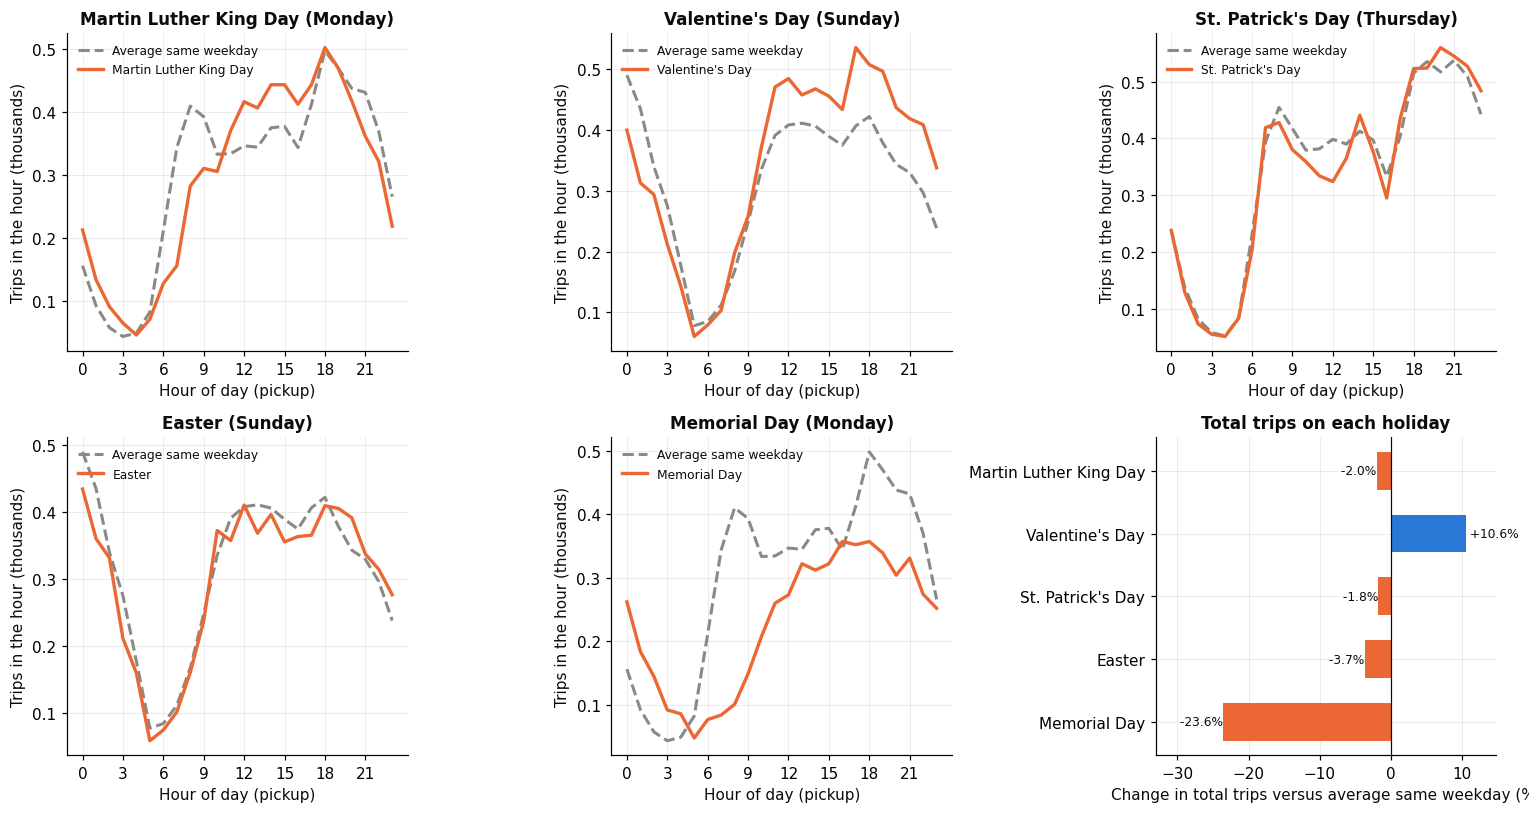

saved q3_4_holidays_hourly.png


In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (name, (hol, base, _)) in zip(axes.ravel(), curves.items()):
    ax.plot(base.index, base.values / 1000, color=GREY, lw=2, ls="--", label="Average same weekday")
    ax.plot(hol.index, hol.values / 1000, color=ORANGE, lw=2.2, label=name)
    ax.set_title(f"{name} ({HOLIDAYS[name].day_name()})")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Hour of day (pickup)")
    ax.set_ylabel("Trips in the hour (thousands)")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
ax = axes[1, 2]
chg = holiday_table.set_index("holiday")["change_%"]
ax.barh(chg.index[::-1], chg.values[::-1], color=[BLUE if v >= 0 else ORANGE for v in chg.values[::-1]], height=0.6)
for i, v in enumerate(chg.values[::-1]):
    ax.text(v, i, f" {v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Change in total trips versus average same weekday (%)")
ax.set_title("Total trips on each holiday")
ax.set_xlim(min(chg.min() * 1.4, -5), max(chg.max() * 1.4, 5))
fig.tight_layout()
save(fig, "q3_4_holidays_hourly.png")

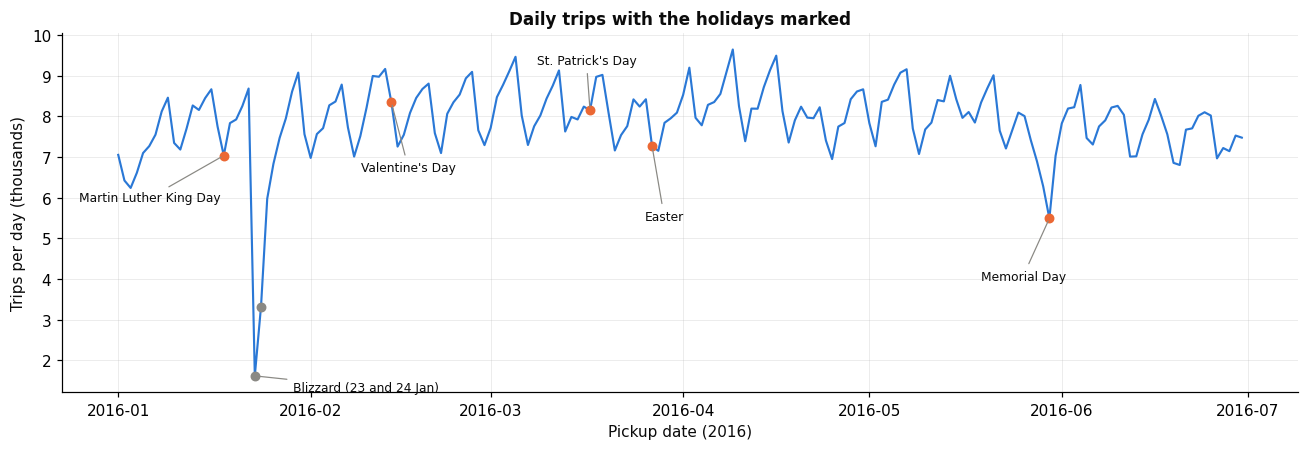

saved q3_4_daily_series.png


In [20]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(daily.index, daily.trips / 1000, color=BLUE, lw=1.4)
offsets = {"Martin Luther King Day": (-95, -30), "Valentine's Day": (-20, -45), "St. Patrick's Day": (-35, 30),
           "Easter": (-5, -48), "Memorial Day": (-45, -40)}
for name, d in HOLIDAYS.items():
    y = daily.loc[d, "trips"] / 1000
    ax.scatter([d], [y], color=ORANGE, zorder=3, s=30)
    ax.annotate(name, (d, y), xytext=offsets[name], textcoords="offset points", fontsize=8, color=INK,
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
y = daily.loc[BLIZZARD[0], "trips"] / 1000
ax.scatter(BLIZZARD, daily.loc[BLIZZARD, "trips"] / 1000, color=GREY, zorder=3, s=30)
ax.annotate("Blizzard (23 and 24 Jan)", (BLIZZARD[0], y), xytext=(25, -10), textcoords="offset points", fontsize=8,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_ylabel("Trips per day (thousands)")
ax.set_xlabel("Pickup date (2016)")
ax.set_title("Daily trips with the holidays marked")
fig.tight_layout()
save(fig, "q3_4_daily_series.png")

## 3.5 Average speed through the day

In [21]:
speed_hour = df.groupby("hour").avg_speed_kmh.agg(["mean", "median"]).round(2)
speed_type = df.groupby(["hour", "day_type"]).avg_speed_kmh.mean().unstack("day_type").round(2)
speed_dh = df.groupby(["day_of_week", "hour"]).avg_speed_kmh.mean().unstack("hour").reindex(DAYS)
display(pd.concat([speed_hour, speed_type], axis=1, keys=["overall", "mean by day type"]).T)
print("Fastest hour overall (mean):", speed_hour["mean"].idxmax(), speed_hour["mean"].max())
print("Slowest hour overall (mean):", speed_hour["mean"].idxmin(), speed_hour["mean"].min())
print("Fastest hour weekday:", speed_type.Weekday.idxmax(), " weekend:", speed_type.Weekend.idxmax())
print("Slowest hour weekday:", speed_type.Weekday.idxmin(), " weekend:", speed_type.Weekend.idxmin())

hour                         0      1      2      3      4      5      6   \
overall          mean     17.76  18.54  18.96  20.04  22.32  24.56  20.58   
                 median   16.09  17.04  17.59  18.58  20.63  22.83  19.01   
mean by day type Weekday  19.45  20.52  20.82  21.79  24.23  24.54  19.86   
                 Weekend  15.71  16.85  17.73  18.96  20.61  24.61  25.03   

hour                         7      8      9   ...     14     15     16  \
overall          mean     15.83  13.03  12.67  ...  12.26  12.13  12.61   
                 median   14.33  11.43  10.99  ...  10.93  10.96  11.52   
mean by day type Weekday  14.95  11.89  11.27  ...  11.56  11.40  12.01   
                 Weekend  22.49  19.69  17.93  ...  13.98  13.89  13.96   

hour                         17     18     19     20     21     22     23  
overall          mean     12.54  12.58  13.64  15.20  15.84  16.07  16.95  
                 median   11.52  11.47  12.28  13.71  14.34  14.60  15.31  
mean by day type Weekday  11.95  12.19  13.58  15.27  15.87  16.10  17.08  
                 Weekend  13.99  13.68  13.82  14.98  15.77  16.00  16.61  

[4 rows x 24 columns]

Fastest hour overall (mean): 5 24.56
Slowest hour overall (mean): 15 12.13
Fastest hour weekday: 5  weekend: 6
Slowest hour weekday: 11  weekend: 18


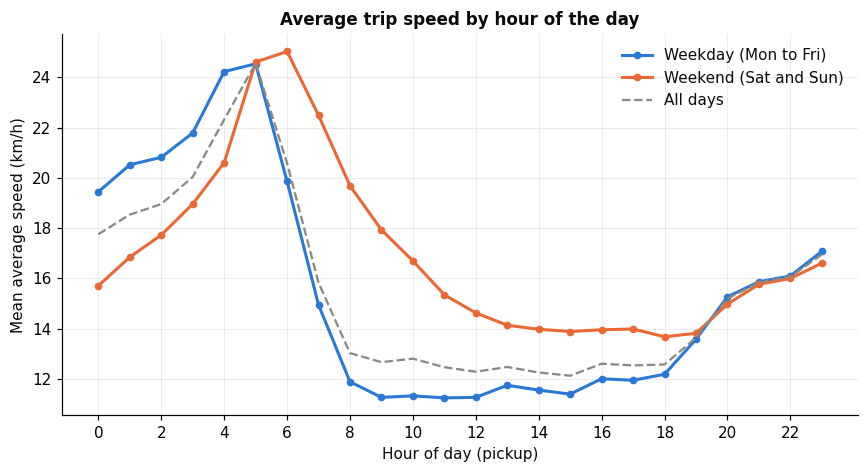

saved q3_5_speed_by_hour.png


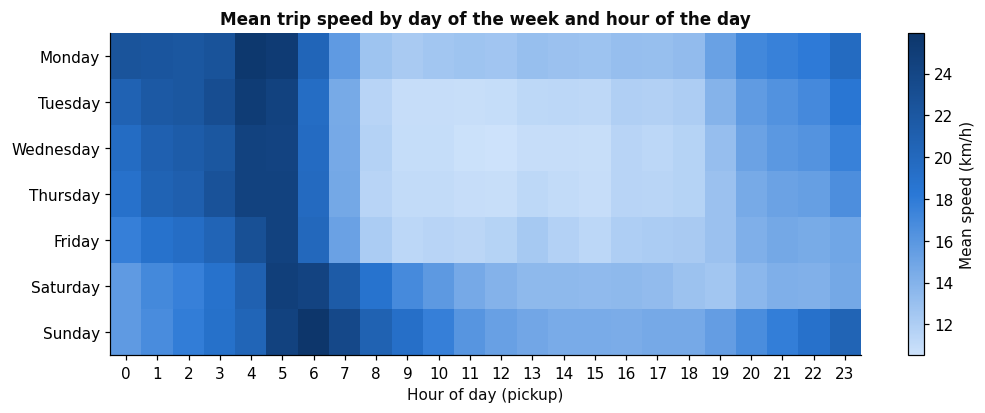

saved q3_5_speed_heatmap.png


In [22]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(speed_type.index, speed_type.Weekday, color=BLUE, lw=2, marker="o", ms=4, label="Weekday (Mon to Fri)")
ax.plot(speed_type.index, speed_type.Weekend, color=ORANGE, lw=2, marker="o", ms=4, label="Weekend (Sat and Sun)")
ax.plot(speed_hour.index, speed_hour["mean"], color=GREY, lw=1.5, ls="--", label="All days")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day (pickup)")
ax.set_ylabel("Mean average speed (km/h)")
ax.set_title("Average trip speed by hour of the day")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "q3_5_speed_by_hour.png")

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(speed_dh.values, aspect="auto", cmap=SEQ)
ax.set_xticks(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(DAYS)
ax.set_xlabel("Hour of day (pickup)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax)
cb.set_label("Mean speed (km/h)")
ax.set_title("Mean trip speed by day of the week and hour of the day")
save(fig, "q3_5_speed_heatmap.png")

# Question 4: Location clusters

All of Question 4 uses **pickup** locations from the cleaned data `df` (1.44 million trips).
The data has no street map, so every map below is drawn from the trips alone: busy streets, avenues and bridges
show up by themselves because that is where people get into taxis. A few reference places are marked on each map to help with orientation.

Distances on the maps are true distances. One degree of longitude at New York's latitude (about 40.7°) is only
about 84 km, compared with 111 km for one degree of latitude, so every map uses an aspect ratio of 1/cos(40.73°).

In [25]:
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from sklearn.cluster import DBSCAN
from scipy import stats as sps
from sklearn.metrics import adjusted_rand_score
from IPython.display import Markdown
import folium
from folium.plugins import HeatMap

HEAT = LinearSegmentedColormap.from_list("heat_blue", ["#e3eefc", "#8fbaf0", "#2a78d6", "#0d366b", "#030f22"])
ORANGE_SEQ = LinearSegmentedColormap.from_list("seq_orange", ["#fde3d6", "#eb6834", "#7a2a0c"])
DIV = LinearSegmentedColormap.from_list("div_blue_orange", ["#0d366b", "#2a78d6", "#f2f2f0", "#eb6834", "#7a2a0c"])

NYC_LAT = 40.73
KM_PER_DEG_LAT = 111.2
KM_PER_DEG_LON = 111.2 * np.cos(np.radians(NYC_LAT))
ASPECT = 1 / np.cos(np.radians(NYC_LAT))

# Map window: all of Manhattan, the parts of Brooklyn and Queens with many pickups, LaGuardia and JFK.
LON0, LON1, LAT0, LAT1 = -74.06, -73.76, 40.62, 40.86
# Manhattan close-up used for the hotspot maps.
ZOOM = (-74.03, -73.94, 40.70, 40.80)

# Reference places (lat, lon) used to label the maps and to name the clusters.
LANDMARKS = {
    "Penn Station": (40.7506, -73.9935), "Grand Central": (40.7527, -73.9772),
    "Times Square": (40.7580, -73.9855), "Port Authority": (40.7570, -73.9903),
    "Rockefeller Center": (40.7587, -73.9787), "Columbus Circle": (40.7681, -73.9819),
    "Midtown East": (40.7577, -73.9700), "Murray Hill": (40.7479, -73.9757),
    "Flatiron / Madison Sq": (40.7411, -73.9897), "Union Square": (40.7359, -73.9911),
    "Gramercy": (40.7368, -73.9845), "Chelsea": (40.7454, -73.9985),
    "Meatpacking": (40.7410, -74.0070), "West Village": (40.7340, -74.0030),
    "Washington Sq / NYU": (40.7308, -73.9973), "East Village": (40.7265, -73.9840),
    "Lower East Side": (40.7205, -73.9880), "SoHo": (40.7233, -74.0030),
    "Tribeca": (40.7163, -74.0086), "Financial District": (40.7069, -74.0113),
    "Upper East Side": (40.7736, -73.9566), "Upper West Side": (40.7810, -73.9800),
    "Hell's Kitchen": (40.7638, -73.9918), "Williamsburg": (40.7177, -73.9577),
    "LaGuardia Airport": (40.7769, -73.8740), "JFK Airport": (40.6413, -73.7781),
}
MAP_LABELS = ["Times Square", "Union Square", "Financial District", "Williamsburg",
              "LaGuardia Airport", "JFK Airport", "Upper East Side", "Upper West Side"]
ZOOM_LABELS = ["Times Square", "Penn Station", "Grand Central", "Union Square", "Washington Sq / NYU",
               "Lower East Side", "Meatpacking", "Columbus Circle"]


def style_map(ax, extent=(LON0, LON1, LAT0, LAT1), labels=MAP_LABELS):
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect(ASPECT)
    ax.grid(False)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    for name in labels:
        la, lo = LANDMARKS[name]
        if extent[0] < lo < extent[1] and extent[2] < la < extent[3]:
            ax.plot(lo, la, marker="o", ms=3.5, mfc="white", mec=INK, mew=0.8, zorder=5)
            right = lo > extent[1] - 0.12 * (extent[1] - extent[0])
            ax.annotate(name, (lo, la), xytext=(-4 if right else 4, 3), textcoords="offset points",
                        ha="right" if right else "left", fontsize=7, color=INK, zorder=5,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))


def nearest_landmark(lat, lon, max_km=0.6):
    names = list(LANDMARKS)
    la = np.array([LANDMARKS[n][0] for n in names])
    lo = np.array([LANDMARKS[n][1] for n in names])
    d = haversine_np(lon, lat, lo, la)
    i = int(np.argmin(d))
    return (f"{names[i]} ({d[i] * 1000:.0f} m)" if d[i] <= max_km else f"other (closest: {names[i]}, {d[i]:.1f} km)")

## 4.1 Heatmaps

**Method.** A scatter plot of 1.4 million points would be slow and would hide density, because points drawn
on top of each other all look the same. Instead the map is cut into a grid of **100 m × 100 m cells** and the
number of pickups in each cell is counted (a 2-D histogram). 100 m is about one short Manhattan block, so single
streets are still visible. The colour scale is **logarithmic**: Midtown cells have thousands of pickups and
outer-borough cells have a handful, and a linear scale would show only Midtown.

**Making the groups comparable.** There are 130 weekdays and 52 weekend days in the data, so raw counts would make
weekdays look busier everywhere. Every map therefore shows the **average number of pickups per day** in each cell.
A third panel shows *where the mix changes*: the ratio of each area's share of weekend (or evening) pickups to its share
of weekday (or morning) pickups, using coarser 400 m cells so the ratio is not dominated by noise. Orange means the area is
relatively more important in the second period, and blue means relatively more important in the first.

**Time periods.** Following Question 3.2, the weekday morning rush builds from 07:00 and the evening peak is at
18:00–19:00. We use **morning = 07:00–09:59** and **evening = 18:00–20:59**. Both windows are three hours long, so they are
directly comparable, and they cover the two commuting peaks. All days of the week are included in both windows.

In [26]:
CELL_KM = 0.1
lon_edges = np.arange(LON0, LON1 + 1e-9, CELL_KM / KM_PER_DEG_LON)
lat_edges = np.arange(LAT0, LAT1 + 1e-9, CELL_KM / KM_PER_DEG_LAT)
COARSE_KM = 0.4
lon_edges_c = np.arange(LON0, LON1 + 1e-9, COARSE_KM / KM_PER_DEG_LON)
lat_edges_c = np.arange(LAT0, LAT1 + 1e-9, COARSE_KM / KM_PER_DEG_LAT)


def grid_counts(mask, lat_e=lat_edges, lon_e=lon_edges):
    H, _, _ = np.histogram2d(df.loc[mask, "pickup_latitude"], df.loc[mask, "pickup_longitude"], bins=[lat_e, lon_e])
    return H


def n_days(mask):
    return df.loc[mask, "date"].nunique()


MORNING_HOURS = range(7, 10)    # 07:00 to 09:59
EVENING_HOURS = range(18, 21)   # 18:00 to 20:59
groups = {
    "Weekday": df.is_weekend == False,
    "Weekend": df.is_weekend == True,
    "Morning (07:00-09:59)": df.hour.isin(MORNING_HOURS),
    "Evening (18:00-20:59)": df.hour.isin(EVENING_HOURS),
}
per_day = {g: grid_counts(m) / n_days(m) for g, m in groups.items()}
coarse = {g: grid_counts(m, lat_edges_c, lon_edges_c) for g, m in groups.items()}
for g, m in groups.items():
    print(f"{g:24s} trips: {int(m.sum()):>9,d}   days: {n_days(m):>3d}   trips per day: {m.sum() / n_days(m):,.0f}")
print("grid:", len(lat_edges) - 1, "x", len(lon_edges) - 1, "cells of", CELL_KM * 1000, "m")

Weekday                  trips: 1,028,623   days: 130   trips per day: 7,912
Weekend                  trips:   410,407   days:  52   trips per day: 7,892
Morning (07:00-09:59)    trips:   187,874   days: 182   trips per day: 1,032
Evening (18:00-20:59)    trips:   261,913   days: 181   trips per day: 1,447
grid: 266 x 252 cells of 100.0 m


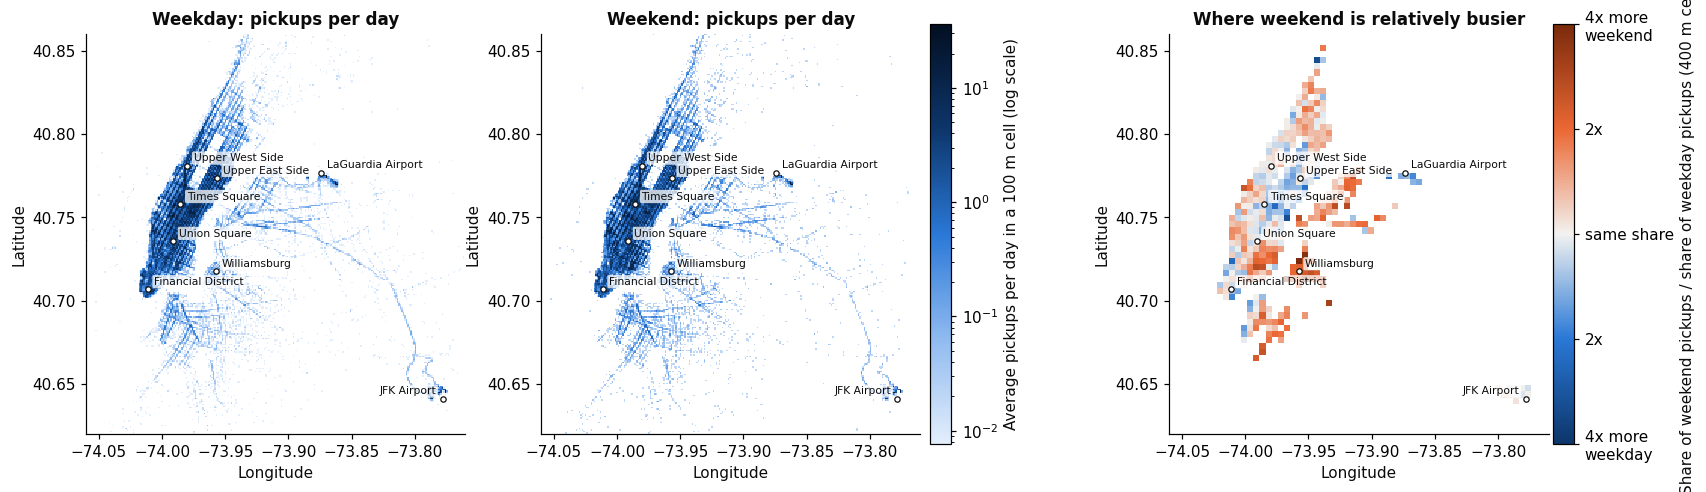

saved q4_1_heatmap_weekday_weekend.png


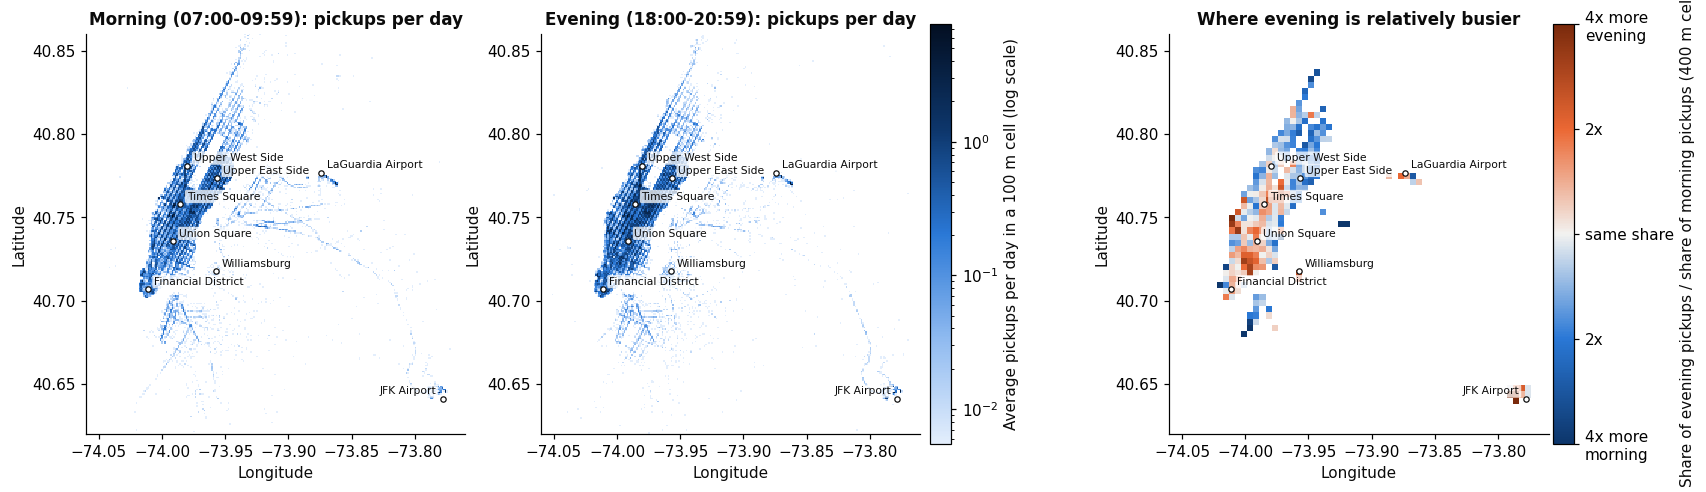

saved q4_1_heatmap_morning_evening.png


In [27]:
def heat_panel(ax, H, title, norm):
    im = ax.imshow(np.ma.masked_less_equal(H, 0), origin="lower", extent=[LON0, LON1, LAT0, LAT1],
                   cmap=HEAT, norm=norm, interpolation="nearest")
    ax.set_title(title)
    style_map(ax)
    return im


def ratio_panel(ax, Ca, Cb, title, min_trips):
    # log2 of (share of period B pickups in the cell) / (share of period A pickups in the cell)
    sa, sb = Ca / Ca.sum(), Cb / Cb.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.log2(sb / sa)
    r = np.ma.masked_where((Ca + Cb < min_trips) | ~np.isfinite(r), np.clip(r, -2, 2))
    im = ax.imshow(r, origin="lower", extent=[LON0, LON1, LAT0, LAT1], cmap=DIV,
                   norm=TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2), interpolation="nearest")
    ax.set_title(title)
    style_map(ax)
    return im


def heat_figure(a, b, fname, min_trips=100):
    both = np.concatenate([per_day[a][per_day[a] > 0], per_day[b][per_day[b] > 0]])
    norm = LogNorm(vmin=np.percentile(both, 5), vmax=np.percentile(both, 99.95))
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.6))
    im = heat_panel(axes[0], per_day[a], f"{a}: pickups per day", norm)
    heat_panel(axes[1], per_day[b], f"{b}: pickups per day", norm)
    cb = fig.colorbar(im, ax=axes[:2], shrink=0.75, pad=0.01)
    cb.set_label("Average pickups per day in a 100 m cell (log scale)")
    im2 = ratio_panel(axes[2], coarse[a], coarse[b], f"Where {b.split(' ')[0].lower()} is relatively busier", min_trips)
    cb2 = fig.colorbar(im2, ax=axes[2], shrink=0.75, pad=0.01, ticks=[-2, -1, 0, 1, 2])
    cb2.ax.set_yticklabels(["4x more\n" + a.split(" ")[0].lower(), "2x", "same share", "2x", "4x more\n" + b.split(" ")[0].lower()])
    cb2.set_label(f"Share of {b.split(' ')[0].lower()} pickups / share of {a.split(' ')[0].lower()} pickups (400 m cells)")
    save(fig, fname)


heat_figure("Weekday", "Weekend", "q4_1_heatmap_weekday_weekend.png")
heat_figure("Morning (07:00-09:59)", "Evening (18:00-20:59)", "q4_1_heatmap_morning_evening.png")

To back the visual comparison with numbers, the next cell measures the share of pickups that fall inside a few
well-known areas (circles that do not overlap) in each period.

In [28]:
AREAS = {  # name: (lat, lon, radius_km)
    "Midtown (Times Sq to Grand Central)": (40.7549, -73.9840, 1.2),
    "Financial District": (40.7075, -74.0110, 1.0),
    "East Village / Lower East Side": (40.7240, -73.9880, 0.8),
    "West Village / Meatpacking": (40.7370, -74.0040, 0.8),
    "Upper East Side": (40.7736, -73.9566, 1.0),
    "Upper West Side": (40.7830, -73.9780, 1.0),
    "Williamsburg (Brooklyn)": (40.7140, -73.9570, 1.0),
    "LaGuardia Airport": (40.7769, -73.8740, 1.5),
    "JFK Airport": (40.6413, -73.7781, 2.0),
}
area_share = {}
for g, m in groups.items():
    sub = df.loc[m, ["pickup_longitude", "pickup_latitude"]]
    area_share[g] = {a: (haversine_np(sub.pickup_longitude, sub.pickup_latitude, lo, la) < r).mean() * 100
                     for a, (la, lo, r) in AREAS.items()}
area_share = pd.DataFrame(area_share).round(2)
area_share["weekend / weekday"] = (area_share["Weekend"] / area_share["Weekday"]).round(2)
area_share["evening / morning"] = (area_share["Evening (18:00-20:59)"] / area_share["Morning (07:00-09:59)"]).round(2)
print("Share of all pickups in the period that start inside each area (%)")
display(area_share)

ws, em = area_share["weekend / weekday"], area_share["evening / morning"]
lines = ["**Q4.1 summary (generated from the data):**", ""]
lines.append("* Weekend pickups are relatively most concentrated in: " + ", ".join(
    f"{a} (share x{v:.2f})" for a, v in ws.sort_values(ascending=False).head(3).items()) + ".")
lines.append("* Weekday pickups are relatively most concentrated in: " + ", ".join(
    f"{a} (weekend share x{v:.2f})" for a, v in ws.sort_values().head(3).items()) + ".")
lines.append("* Evening (18:00-20:59) pickups are relatively most concentrated in: " + ", ".join(
    f"{a} (share x{v:.2f})" for a, v in em.sort_values(ascending=False).head(3).items()) + ".")
lines.append("* Morning (07:00-09:59) pickups are relatively most concentrated in: " + ", ".join(
    f"{a} (evening share x{v:.2f})" for a, v in em.sort_values().head(3).items()) + ".")
lines.append(f"* Midtown alone holds {area_share.iloc[0, :4].min():.1f}-{area_share.iloc[0, :4].max():.1f}% of all pickups in every period.")
display(Markdown("\n".join(lines)))

Share of all pickups in the period that start inside each area (%)


,Weekday,Weekend,Morning (07:00-09:59),Evening (18:00-20:59),weekend / weekday,evening / morning
Midtown (Times Sq to Grand Central),26.10,22.53,23.79,26.29,0.86,1.11
Financial District,3.58,3.25,3.38,3.87,0.91,1.14
East Village / Lower East Side,4.68,8.23,3.12,4.72,1.76,1.51
West Village / Meatpacking,5.25,7.18,4.53,5.34,1.37,1.18
Upper East Side,10.22,8.57,13.39,9.06,0.84,0.68
Upper West Side,4.90,5.09,5.40,5.02,1.04,0.93
Williamsburg (Brooklyn),0.28,0.65,0.09,0.23,2.32,2.56
LaGuardia Airport,2.78,1.91,2.03,2.65,0.69,1.31
JFK Airport,2.12,2.05,1.47,2.13,0.97,1.45


**Q4.1 summary (generated from the data):**

* Weekend pickups are relatively most concentrated in: Williamsburg (Brooklyn) (share x2.32), East Village / Lower East Side (share x1.76), West Village / Meatpacking (share x1.37).
* Weekday pickups are relatively most concentrated in: LaGuardia Airport (weekend share x0.69), Upper East Side (weekend share x0.84), Midtown (Times Sq to Grand Central) (weekend share x0.86).
* Evening (18:00-20:59) pickups are relatively most concentrated in: Williamsburg (Brooklyn) (share x2.56), East Village / Lower East Side (share x1.51), JFK Airport (share x1.45).
* Morning (07:00-09:59) pickups are relatively most concentrated in: Upper East Side (evening share x0.68), Upper West Side (evening share x0.93), Midtown (Times Sq to Grand Central) (evening share x1.11).
* Midtown alone holds 22.5-26.3% of all pickups in every period.

In [29]:
# Interactive version: one switchable layer per period (open q4_1_heatmaps.html in a browser).
# The points are 250 m cell centres weighted by pickups per day, so the file stays small.
def cell_points(mask, cell_km=0.25):
    sub = df.loc[mask]
    la = (sub.pickup_latitude / (cell_km / KM_PER_DEG_LAT)).round() * (cell_km / KM_PER_DEG_LAT)
    lo = (sub.pickup_longitude / (cell_km / KM_PER_DEG_LON)).round() * (cell_km / KM_PER_DEG_LON)
    c = pd.DataFrame({"la": la, "lo": lo}).groupby(["la", "lo"]).size() / n_days(mask)
    c = c[c >= 0.05]
    return [[a, b, float(w)] for (a, b), w in c.items()]


m = folium.Map(location=[40.745, -73.96], zoom_start=12, tiles="cartodbpositron")
for i, (g, mask) in enumerate(groups.items()):
    HeatMap(cell_points(mask), name=g, radius=9, blur=12, max_zoom=14, show=(i == 0)).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save("q4_1_heatmaps.html")
print("saved q4_1_heatmaps.html")

saved q4_1_heatmaps.html


### Findings for 4.1

* **Manhattan dominates in every period.** The densest cells form a solid block from about 14th Street to
  59th Street (Midtown and Midtown South), with sharp lines along the avenues and around Penn Station,
  Grand Central and Times Square. Outside Manhattan, the only strong spots are **LaGuardia** and **JFK**, plus
  north-west Brooklyn (Williamsburg and Downtown Brooklyn) and Long Island City. Most of Brooklyn and Queens is nearly empty, because
  yellow cabs mostly pick up in Manhattan and at the airports (green "boro" taxis serve the outer boroughs).
* **Weekday vs weekend.** On weekdays pickups are concentrated in the business districts: Midtown, around Grand Central
  and Penn Station, and the Financial District. At weekends the share of trips moves **downtown and across the river**,
  to the East Village, Lower East Side, West Village/Meatpacking, SoHo and Williamsburg. These are restaurant and nightlife areas,
  which matches Question 3.3, where weekend activity peaks after midnight. The Financial District loses most of its share at
  weekends because offices are closed. LaGuardia's share also drops at weekends (much of its traffic is weekday business travel),
  while JFK's share stays about the same.
* **Morning vs evening.** Morning pickups (07:00–09:59) are relatively more important in **residential areas**, such as the Upper East
  and Upper West Side, and at the transit hubs (Penn Station, Grand Central), where commuters take a taxi to work.
  Evening pickups (18:00–20:59) shift to **Midtown and downtown**, where offices empty out and people head to restaurants,
  theatres (Times Square) and bars. Put together, the two maps show the daily commute in two directions: home areas in the morning and work and
  entertainment areas in the evening.

*(The exact percentages are in the area-share table and the generated summary above. The ratio "x1.74" means the area's
share of pickups is 1.74 times higher in the second period than in the first.)*

## 4.2 Hotspots with DBSCAN

**Time windows** (pickup time):
* **Friday night:** Friday 23:00 to Saturday 01:59, i.e. 3 hours per week.
* **Thursday evening:** Thursday 17:00 to 19:59, i.e. 3 hours per week.

The data covers 26 weeks, so each window holds 26 × 3 = **78 hours** of pickups. These are pooled, which gives the
*typical* hotspots in that window rather than those of one particular night.

**Parameters.**
* **ε (eps) = 100 m.** This is about one short Manhattan block (street-to-street blocks are about 80 m and avenue blocks about 250 m),
  so all pickups in a cluster are within a short walk, and a driver would treat them as "the same spot".
  GPS in Midtown's tall-building canyons is often off by tens of metres, so pickups at one spot are scattered. With ε = 50 m,
  a 50 m circle rarely holds enough pickups: at our threshold only a handful of clusters survive, and at low thresholds
  one spot breaks into hundreds of fragments. With ε ≥ 150 m, neighbouring hotspots chain together into clusters
  several kilometres wide (see the sensitivity analysis below).
* **min_samples: converting "15 pickups per hour" into a DBSCAN count.** DBSCAN has no notion of time. `min_samples` is simply
  the number of pickups that must lie within ε of a point *in the data we give it*. We give it all 78 hours of a window at once,
  so a rate of *r* pickups per hour becomes **`min_samples = r × 78`**. Pooling 26 weeks does not lower the bar: a spot that
  averages 1.5 pickups per hour over 78 hours is exactly a spot with at least 117 pickups within 100 m in the pooled data.

  **Why not r = 15?** Taken literally in this dataset, 15 per hour means `min_samples = 15 × 78 = 1 170` pickups within 100 m.
  The dataset is a small sample: the line printed above shows only a few hundred pickups per hour in the *whole city* during each window.
  One 100 m circle would need several percent of all of New York's pickups. The check cell below runs exactly this setting, and also
  the "15 pickups within 100 m in a single hour" version on each of the 78 hours separately. It shows that DBSCAN finds (almost) no
  hotspots at all. The literal threshold is therefore not usable on this sample. The brief's 15 per hour describes the real taxi fleet,
  and the Kaggle file only contains a fraction of the fleet's trips.

  **Why r = 1.5?** We chose the rate from the sensitivity analysis below, not by assumption:
  * Below about 0.5 pickups per hour, or with ε ≥ 150 m, the largest "hotspot" is 2–4 km across, i.e. half of Midtown chained together.
    A driver cannot use that as a place to wait.
  * At 1.5 per hour, every cluster stays within a few hundred metres, and there are still many of them (exact count printed below).
  * Higher thresholds keep only a few clusters and drop spots that are clearly busy on the heatmap.

  So 1.5 per hour is lower than 15 *in the sample's units*, but it describes the same idea the brief has in mind: a compact spot that
  reliably produces a steady stream of pickups.

**Implementation details.**
* The haversine metric is used with the ball tree, so ε is a true distance on the Earth's surface
  (ε in radians = km / 6371.0088, as in the brief's example code).
* **Pickup counts as weights.** To keep DBSCAN fast and light on memory, coordinates are rounded to 4 decimals (about 11 m × 8 m).
  All pickups at the same rounded spot become **one point whose `sample_weight` is the number of pickups there**. In scikit-learn's
  DBSCAN, a point is a core point when the *sum of the weights* of its neighbours within ε is at least `min_samples`. A spot with weight 5
  therefore counts exactly like 5 separate pickups. The only change is that each pickup is moved by at most about 7 m, far less than ε = 100 m.
  The check cell below confirms this by clustering the raw, unrounded points of the Thursday window and comparing the two results.

In [30]:
KMS_PER_RADIAN = 6371.0088
WINDOWS = {
    "Friday 23:00 - Saturday 02:00": ((df.dow == 4) & (df.hour == 23)) | ((df.dow == 5) & (df.hour < 2)),
    "Thursday 17:00 - 20:00": (df.dow == 3) & df.hour.between(17, 19),
}


def window_hours(mask):
    # number of distinct (date, hour) slots in the window, i.e. hours of observation
    return df.loc[mask, ["date", "hour"]].drop_duplicates().shape[0]


def weighted_points(mask):
    sub = df.loc[mask]
    pts = (sub.assign(lat=sub.pickup_latitude.round(4), lon=sub.pickup_longitude.round(4))
              .groupby(["lat", "lon"]).size().rename("w").reset_index())
    return pts


def run_dbscan(pts, eps_m, min_samples):
    db = DBSCAN(eps=eps_m / 1000 / KMS_PER_RADIAN, min_samples=min_samples,
                algorithm="ball_tree", metric="haversine")
    db.fit(np.radians(pts[["lat", "lon"]].values), sample_weight=pts.w.values)
    return db.labels_


def cluster_summary(pts, labels, hours):
    p = pts.assign(cluster=labels)
    p = p[p.cluster >= 0]
    rows = []
    for c, g in p.groupby("cluster"):
        lat = np.average(g.lat, weights=g.w)
        lon = np.average(g.lon, weights=g.w)
        d = haversine_np(g.lon.values, g.lat.values, lon, lat)
        order = np.argsort(d)
        cum = np.cumsum(g.w.values[order]) / g.w.sum()
        r90 = d[order][np.searchsorted(cum, 0.9)]
        rows.append({"old": c, "pickups": int(g.w.sum()), "pickups_per_hour": round(g.w.sum() / hours, 2),
                     "lat": round(lat, 5), "lon": round(lon, 5), "radius_90%_m": int(round(r90 * 1000)),
                     "nearest_place": nearest_landmark(lat, lon)})
    cols = ["old", "pickups", "pickups_per_hour", "lat", "lon", "radius_90%_m", "nearest_place"]
    t = pd.DataFrame(rows, columns=cols).sort_values("pickups", ascending=False).reset_index(drop=True)
    t.index = t.index + 1
    t.index.name = "hotspot"
    remap = {old: new for new, old in zip(t.index, t.old)}
    return t.drop(columns="old"), np.array([remap.get(l, -1) for l in labels])


win_pts, win_hours = {}, {}
for name, mask in WINDOWS.items():
    win_pts[name] = weighted_points(mask)
    win_hours[name] = window_hours(mask)
    print(f"{name}: {int(mask.sum()):,d} pickups, {win_hours[name]} hours observed, "
          f"{int(mask.sum()) / win_hours[name]:.0f} pickups per hour city-wide, {len(win_pts[name]):,d} distinct 10 m spots")

Friday 23:00 - Saturday 02:00: 34,440 pickups, 78 hours observed, 442 pickups per hour city-wide, 25,121 distinct 10 m spots
Thursday 17:00 - 20:00: 37,827 pickups, 78 hours observed, 485 pickups per hour city-wide, 28,798 distinct 10 m spots


### Parameter sensitivity

For each window, DBSCAN is run over a grid of ε values (50–200 m) and thresholds (0.25–4 pickups per hour).
Two things are tracked: the **number of clusters**, and the **size of the largest cluster**
(the radius around its centre that holds 90 % of its pickups). A radius of several kilometres means DBSCAN has chained
a whole district of Manhattan into one blob. A driver cannot use that as "a place to wait", so a good setting keeps every
cluster within a few hundred metres while still finding many clusters.

In [31]:
EPS_GRID = [50, 100, 150, 200]
RATE_GRID = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
sens_rows = []
for name, pts in win_pts.items():
    H = win_hours[name]
    for eps in EPS_GRID:
        for rate in RATE_GRID:
            ms = int(np.ceil(rate * H))
            lab = run_dbscan(pts, eps, ms)
            w = pts.w.values
            t, _ = cluster_summary(pts, lab, H)
            sens_rows.append({"window": name, "eps_m": eps, "rate_per_hour": rate, "min_samples": ms,
                              "clusters": len(t),
                              "share_of_pickups_in_clusters_%": round(w[lab >= 0].sum() / w.sum() * 100, 1),
                              "largest_cluster_radius_m": t["radius_90%_m"].max() if len(t) else np.nan})
sens = pd.DataFrame(sens_rows)
display(sens.pivot_table(index=["window", "eps_m"], columns="rate_per_hour", values="clusters"))
display(sens.pivot_table(index=["window", "eps_m"], columns="rate_per_hour", values="largest_cluster_radius_m"))

rate_per_hour                         0.25   0.50  1.00  1.50  2.00  3.00  \
window                        eps_m                                         
Friday 23:00 - Saturday 02:00 50     180.0  113.0  37.0  12.0   4.0   0.0   
                              100     46.0   44.0  49.0  36.0  22.0   7.0   
                              150     25.0   20.0  18.0  19.0  16.0  14.0   
                              200     20.0   10.0  10.0  10.0   8.0   9.0   
Thursday 17:00 - 20:00        50     238.0  116.0  21.0   7.0   6.0   1.0   
                              100     30.0   60.0  44.0  31.0  16.0   5.0   
                              150     18.0   12.0  30.0  18.0  19.0  11.0   
                              200     10.0   10.0   9.0  10.0  14.0  14.0   

rate_per_hour                        4.00  
window                        eps_m        
Friday 23:00 - Saturday 02:00 50      0.0  
                              100     1.0  
                              150    10.0  
                              200     8.0  
Thursday 17:00 - 20:00        50      1.0  
                              100     3.0  
                              150     8.0  
                              200    11.0

rate_per_hour                          0.25    0.50    1.00    1.50    2.00  \
window                        eps_m                                           
Friday 23:00 - Saturday 02:00 50      747.0   388.0   154.0    90.0    62.0   
                              100    2835.0  2518.0   870.0   354.0   305.0   
                              150    3849.0  2859.0  2600.0  1774.0  1104.0   
                              200    3943.0  3857.0  2857.0  2742.0  2621.0   
Thursday 17:00 - 20:00        50     1954.0   501.0   120.0    92.0    92.0   
                              100    3887.0  3265.0   883.0   567.0   241.0   
                              150    4155.0  3932.0  3420.0  2400.0  1095.0   
                              200    4195.0  4145.0  3919.0  3527.0  3384.0   

rate_per_hour                          3.00    4.00  
window                        eps_m                  
Friday 23:00 - Saturday 02:00 50        NaN     NaN  
                              100     204.0    93.0  
                              150     543.0   327.0  
                              200    1768.0   906.0  
Thursday 17:00 - 20:00        50       50.0    45.0  
                              100     164.0   110.0  
                              150     605.0   271.0  
                              200    1233.0  1104.0

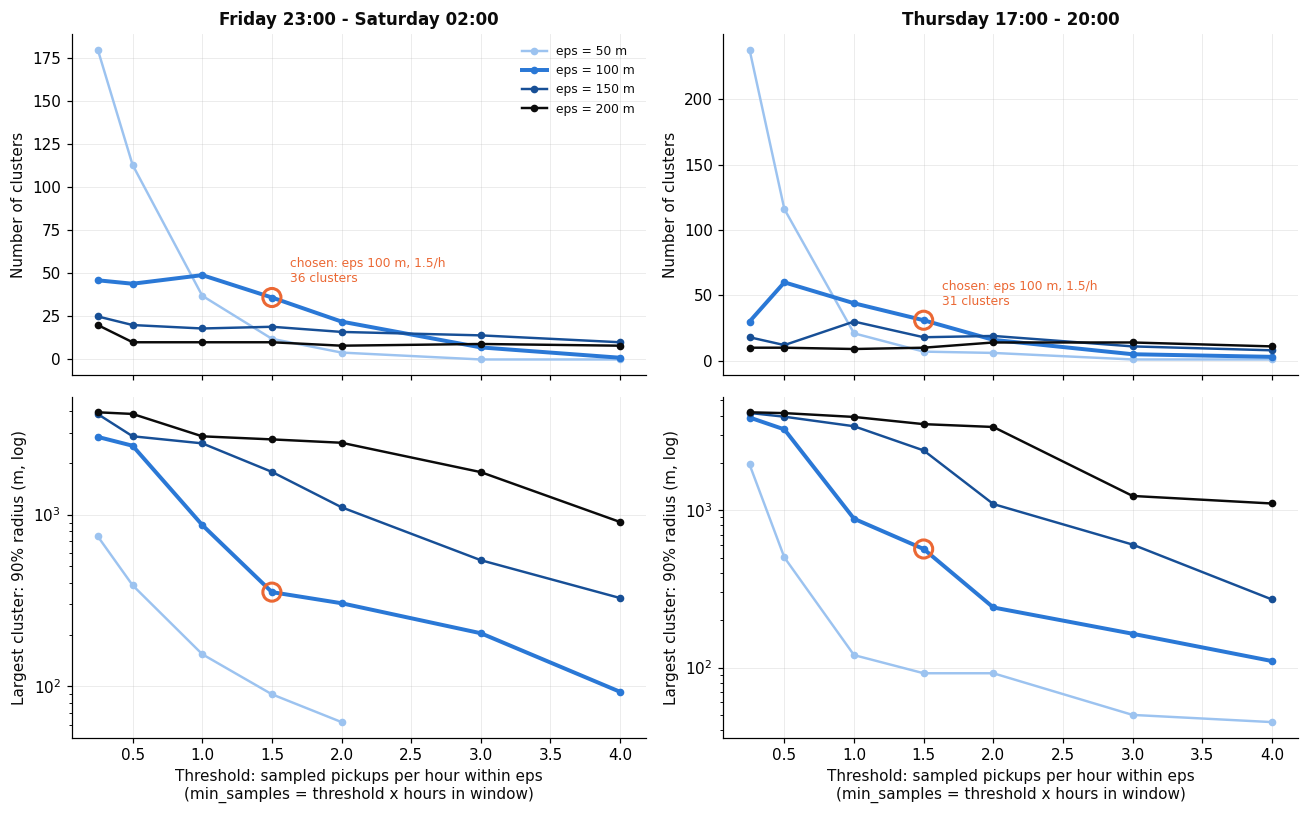

saved q4_2_dbscan_parameter_sensitivity.png


In [32]:
EPS_M, RATE = 100, 1.5
eps_colours = dict(zip(EPS_GRID, ["#9cc3f0", "#2a78d6", "#174f96", "#0b0b0b"]))
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for j, name in enumerate(WINDOWS):
    s = sens[sens.window == name]
    for eps in EPS_GRID:
        e = s[s.eps_m == eps]
        lw = 2.6 if eps == EPS_M else 1.6
        axes[0, j].plot(e.rate_per_hour, e.clusters, marker="o", ms=4, lw=lw, color=eps_colours[eps], label=f"eps = {eps} m")
        axes[1, j].plot(e.rate_per_hour, e["largest_cluster_radius_m"], marker="o", ms=4, lw=lw, color=eps_colours[eps], label=f"eps = {eps} m")
    chosen = s[(s.eps_m == EPS_M) & (s.rate_per_hour == RATE)].iloc[0]
    axes[0, j].scatter([RATE], [chosen.clusters], s=140, facecolor="none", edgecolor=ORANGE, lw=2, zorder=5)
    axes[1, j].scatter([RATE], [chosen["largest_cluster_radius_m"]], s=140, facecolor="none", edgecolor=ORANGE, lw=2, zorder=5)
    axes[0, j].annotate(f"chosen: eps {EPS_M} m, {RATE}/h\n{int(chosen.clusters)} clusters", (RATE, chosen.clusters),
                        xytext=(12, 10), textcoords="offset points", color=ORANGE, fontsize=8)
    axes[0, j].set_title(name)
    axes[0, j].set_ylabel("Number of clusters")
    axes[1, j].set_ylabel("Largest cluster: 90% radius (m, log)")
    axes[1, j].set_xlabel("Threshold: sampled pickups per hour within eps\n(min_samples = threshold x hours in window)")
    axes[1, j].set_yscale("log")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "q4_2_dbscan_parameter_sensitivity.png")

In [33]:
# Check 1: the brief's literal threshold of 15 pickups per hour
lit_rows = []
for name, mask in WINDOWS.items():
    H = win_hours[name]
    lab = run_dbscan(win_pts[name], 100, 15 * H)          # pooled: 15 x 78 pickups within 100 m
    # single-hour version: run DBSCAN on each of the 78 hours separately with min_samples = 15
    hours_with_cluster, clusters_per_hour = 0, []
    sub = df.loc[mask, ["date", "hour", "pickup_latitude", "pickup_longitude"]]
    for _, g in sub.groupby(["date", "hour"]):
        hl = DBSCAN(eps=0.1 / KMS_PER_RADIAN, min_samples=15, algorithm="ball_tree", metric="haversine").fit(
            np.radians(g[["pickup_latitude", "pickup_longitude"]].values)).labels_
        clusters_per_hour.append(hl.max() + 1)
    lit_rows.append({"window": name, "pooled: min_samples = 15 x %d" % H: int(lab.max() + 1),
                     "single hours with >= 1 cluster": f"{int((np.array(clusters_per_hour) > 0).sum())} of {H}",
                     "mean clusters per single hour": round(float(np.mean(clusters_per_hour)), 2)})
print("Clusters found with the literal threshold of 15 pickups per hour (eps = 100 m):")
display(pd.DataFrame(lit_rows).set_index("window"))

# Check 2: weighted 10 m spots give the same clusters as the raw points
name = "Thursday 17:00 - 20:00"
ms = int(np.ceil(RATE * win_hours[name]))
raw = df.loc[WINDOWS[name], ["pickup_latitude", "pickup_longitude"]].reset_index(drop=True)
raw_lab = DBSCAN(eps=EPS_M / 1000 / KMS_PER_RADIAN, min_samples=ms, algorithm="ball_tree", metric="haversine").fit(
    np.radians(raw.values)).labels_
pts = win_pts[name].assign(wlab=run_dbscan(win_pts[name], EPS_M, ms))
raw = raw.assign(lat=raw.pickup_latitude.round(4), lon=raw.pickup_longitude.round(4), raw_lab=raw_lab)
raw = raw.merge(pts[["lat", "lon", "wlab"]], on=["lat", "lon"], how="left")
agree = ((raw.raw_lab >= 0) == (raw.wlab >= 0)).mean() * 100
print(f"{name}: raw points -> {raw_lab.max() + 1} clusters, weighted 10 m spots -> {pts.wlab.max() + 1} clusters")
print(f"same hotspot/noise decision for {agree:.1f}% of pickups, adjusted Rand index = {adjusted_rand_score(raw.raw_lab, raw.wlab):.3f}")

Clusters found with the literal threshold of 15 pickups per hour (eps = 100 m):


,pooled: min_samples = 15 x 78,single hours with >= 1 cluster,mean clusters per single hour
window,,,
Friday 23:00 - Saturday 02:00,0,0 of 78,0.0
Thursday 17:00 - 20:00,0,0 of 78,0.0


Thursday 17:00 - 20:00: raw points -> 31 clusters, weighted 10 m spots -> 31 clusters
same hotspot/noise decision for 98.3% of pickups, adjusted Rand index = 0.951


### Final clustering, hotspot tables and maps

In [34]:
hotspots, hot_labels = {}, {}
for name, pts in win_pts.items():
    ms = int(np.ceil(RATE * win_hours[name]))
    lab = run_dbscan(pts, EPS_M, ms)
    hotspots[name], hot_labels[name] = cluster_summary(pts, lab, win_hours[name])
    t = hotspots[name]
    share = t.pickups.sum() / pts.w.sum() * 100
    print(f"\n{name}: eps = {EPS_M} m, min_samples = {ms}  ->  {len(t)} clusters "
          f"holding {share:.1f}% of the window's pickups")
    display(t)


Friday 23:00 - Saturday 02:00: eps = 100 m, min_samples = 117  ->  36 clusters holding 38.8% of the window's pickups


,pickups,pickups_per_hour,lat,lon,radius_90%_m,nearest_place
hotspot,,,,,,
1,1584,20.31,40.72091,-73.98822,317,Lower East Side (49 m)
2,1005,12.88,40.73103,-73.98756,304,East Village (586 m)
3,941,12.06,40.75963,-73.98886,354,Port Authority (317 m)
4,913,11.71,40.74094,-74.00589,231,Meatpacking (94 m)
5,874,11.21,40.72968,-74.00062,303,Washington Sq / NYU (306 m)
6,627,8.04,40.72605,-73.99202,225,"other (closest: East Village, 0.7 km)"
7,615,7.88,40.74788,-73.98688,241,"other (closest: Penn Station, 0.6 km)"
8,537,6.88,40.73383,-74.00258,238,West Village (40 m)
9,518,6.64,40.72670,-73.98450,211,East Village (48 m)



Thursday 17:00 - 20:00: eps = 100 m, min_samples = 117  ->  31 clusters holding 30.4% of the window's pickups


,pickups,pickups_per_hour,lat,lon,radius_90%_m,nearest_place
hotspot,,,,,,
1,2009,25.76,40.76027,-73.97040,567,Midtown East (287 m)
2,847,10.86,40.75178,-73.97665,266,Grand Central (113 m)
3,783,10.04,40.76676,-73.98181,284,Columbus Circle (149 m)
4,610,7.82,40.76301,-73.97393,269,"other (closest: Rockefeller Center, 0.6 km)"
5,601,7.71,40.74976,-73.99168,207,Penn Station (179 m)
6,578,7.41,40.74202,-73.98516,291,Flatiron / Madison Sq (396 m)
7,544,6.97,40.76955,-73.86330,94,"other (closest: LaGuardia Airport, 1.2 km)"
8,527,6.76,40.77394,-73.87241,176,LaGuardia Airport (355 m)
9,413,5.29,40.75095,-73.99426,189,Penn Station (75 m)


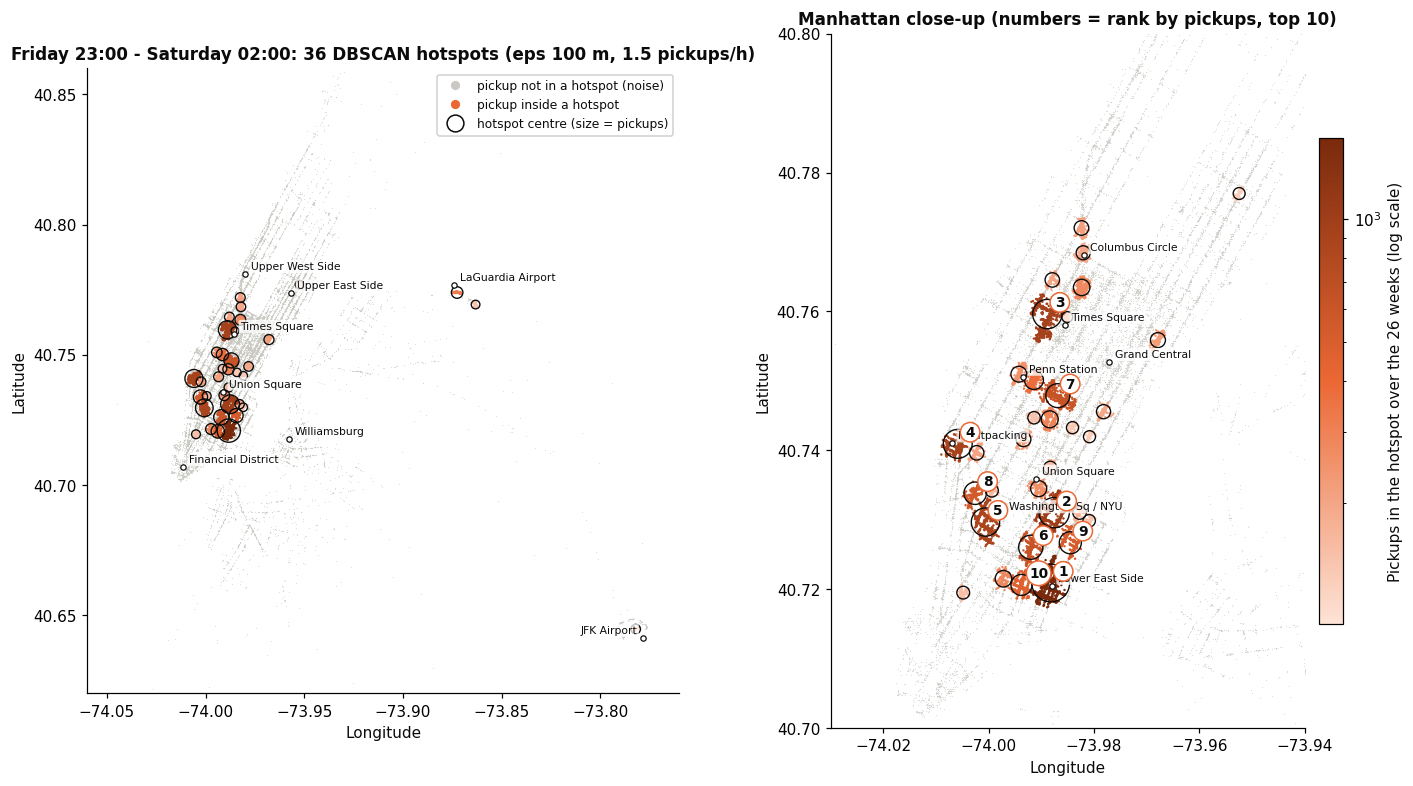

saved q4_2_hotspots_friday_night.png


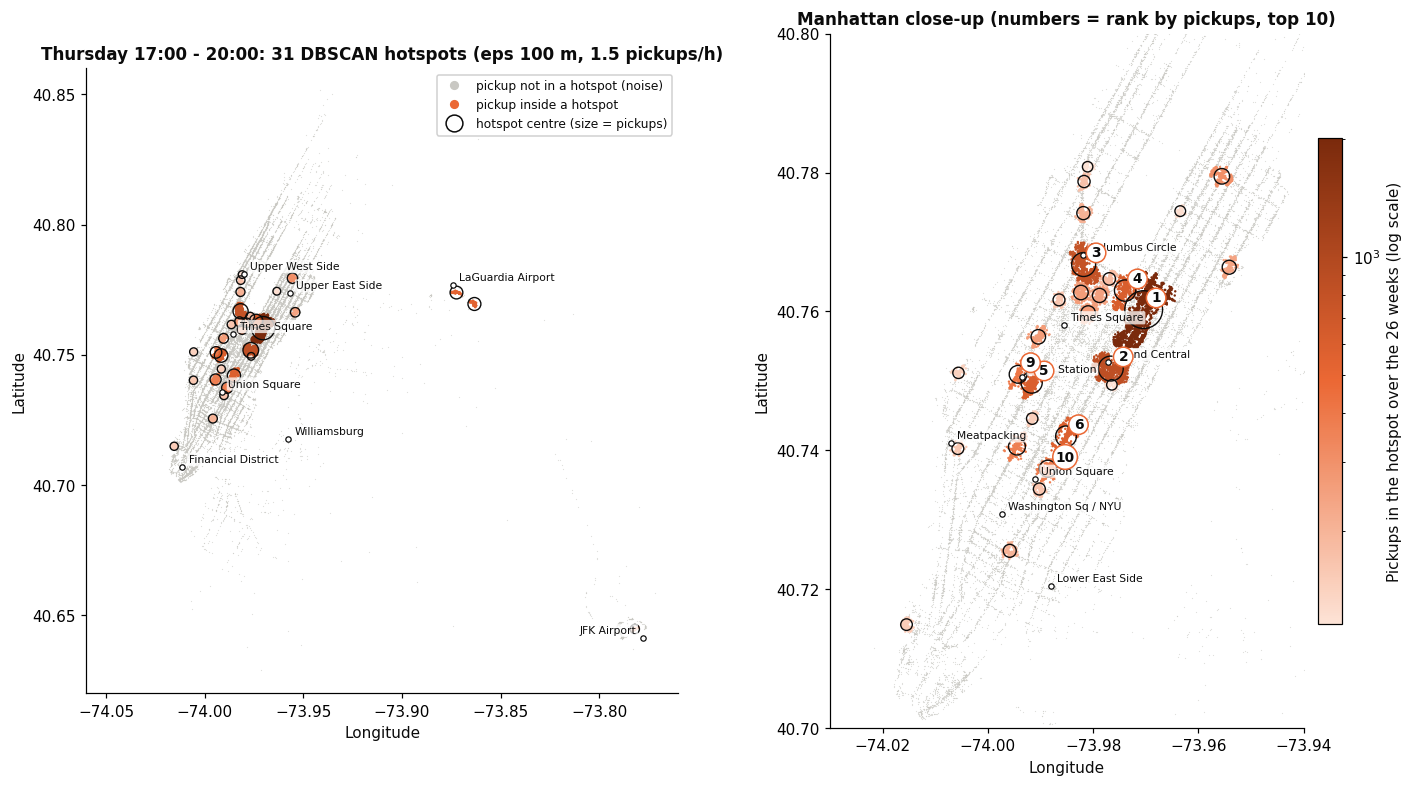

saved q4_2_hotspots_thursday_evening.png


In [35]:
def hotspot_map(name, fname, n_label=10):
    pts, lab, t = win_pts[name], hot_labels[name], hotspots[name]
    fig, axes = plt.subplots(1, 2, figsize=(17, 8.2), gridspec_kw={"width_ratios": [1.15, 1]})
    size_norm = LogNorm(vmin=max(t.pickups.min(), 1), vmax=t.pickups.max())
    for ax, extent, labels, smax in [(axes[0], (LON0, LON1, LAT0, LAT1), MAP_LABELS, 220), (axes[1], ZOOM, ZOOM_LABELS, 600)]:
        bg = pts[lab < 0]
        ax.scatter(bg.lon, bg.lat, s=0.6, color="#c9c8c3", alpha=0.6, rasterized=True, lw=0)
        cl = pts[lab >= 0]
        sizes = t.pickups.reindex(lab[lab >= 0]).values
        sc = ax.scatter(cl.lon, cl.lat, s=2.5, c=sizes, cmap=ORANGE_SEQ, norm=size_norm, rasterized=True, lw=0)
        ax.scatter(t.lon, t.lat, s=12 + smax * t.pickups / t.pickups.max(), facecolor="none", edgecolor=INK, lw=0.9, zorder=4)
        style_map(ax, extent, labels)
    for i, r in t.head(n_label).iterrows():
        if ZOOM[0] < r.lon < ZOOM[1] and ZOOM[2] < r.lat < ZOOM[3]:
            axes[1].annotate(str(i), (r.lon, r.lat), xytext=(5, 5), textcoords="offset points", fontsize=9,
                             fontweight="bold", color=INK, zorder=6,
                             bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=ORANGE, lw=1))
    axes[0].set_title(f"{name}: {len(t)} DBSCAN hotspots (eps {EPS_M} m, {RATE} pickups/h)")
    axes[1].set_title(f"Manhattan close-up (numbers = rank by pickups, top {n_label})")
    cb = fig.colorbar(sc, ax=axes, shrink=0.7, pad=0.01)
    cb.set_label("Pickups in the hotspot over the 26 weeks (log scale)")
    handles = [Line2D([], [], ls="none", marker="o", ms=5, color="#c9c8c3", label="pickup not in a hotspot (noise)"),
               Line2D([], [], ls="none", marker="o", ms=5, color=ORANGE, label="pickup inside a hotspot"),
               Line2D([], [], ls="none", marker="o", ms=11, mfc="none", mec=INK, label="hotspot centre (size = pickups)")]
    axes[0].legend(handles=handles, loc="upper right", fontsize=8, frameon=True, framealpha=0.9)
    save(fig, fname)


hotspot_map("Friday 23:00 - Saturday 02:00", "q4_2_hotspots_friday_night.png")
hotspot_map("Thursday 17:00 - 20:00", "q4_2_hotspots_thursday_evening.png")

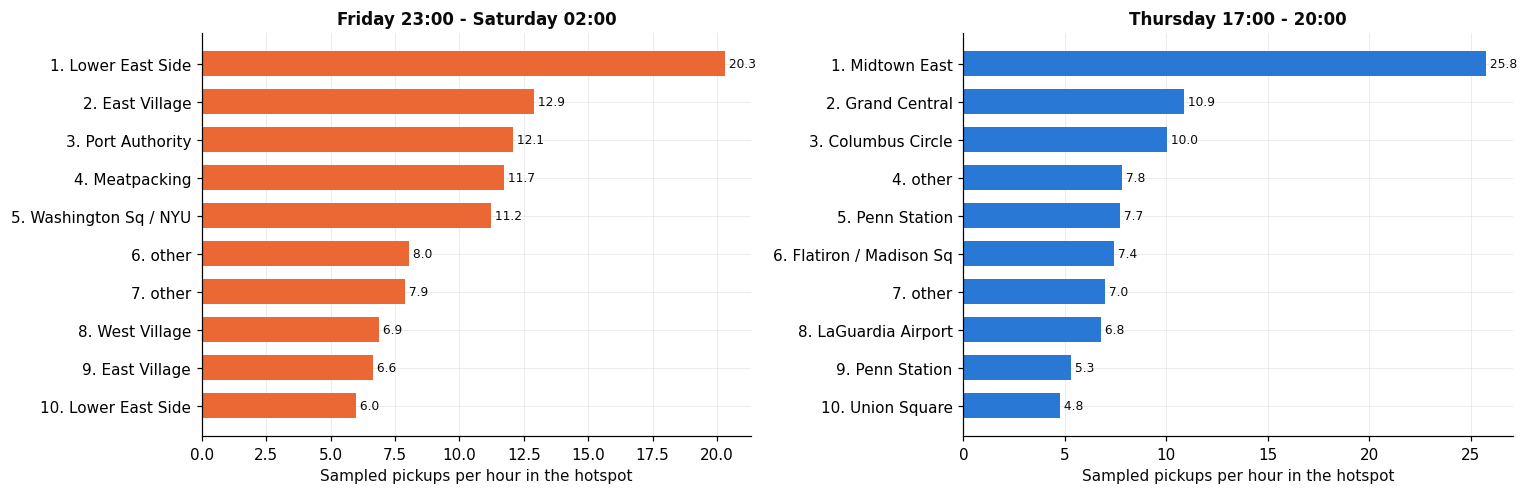

saved q4_2_top_hotspots.png
Friday-night hotspots that are also Thursday-evening hotspots (within 200 m): 13 of 36
Friday-only hotspots: Lower East Side, East Village, Port Authority, Washington Sq / NYU, other, other, West Village, East Village, Lower East Side, Flatiron / Madison Sq, SoHo, Midtown East, Columbus Circle, Meatpacking, Hell's Kitchen


**Q4.2 summary (generated from the data):**

* **Friday 23:00 - Saturday 02:00:** DBSCAN (eps = 100 m, min_samples = 117) found **36 clusters**, holding 38.8% of the window's pickups. The median hotspot has 90% of its pickups within 146 m (largest 354 m). Top 5: 1. Lower East Side (20.3/h); 2. East Village (12.9/h); 3. Port Authority (12.1/h); 4. Meatpacking (11.7/h); 5. Washington Sq / NYU (11.2/h).
* **Thursday 17:00 - 20:00:** DBSCAN (eps = 100 m, min_samples = 117) found **31 clusters**, holding 30.4% of the window's pickups. The median hotspot has 90% of its pickups within 147 m (largest 567 m). Top 5: 1. Midtown East (25.8/h); 2. Grand Central (10.9/h); 3. Columbus Circle (10.0/h); 4. other (7.8/h); 5. Penn Station (7.7/h).
* 13 of the 36 Friday-night hotspots are also Thursday-evening hotspots (centres within 200 m).

In [36]:
# Top 10 hotspots in each window, ranked by pickups per hour
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, name in zip(axes, WINDOWS):
    t = hotspots[name].head(10).iloc[::-1]
    labels = [f"{i}. {p.split(' (')[0]}" for i, p in zip(t.index, t.nearest_place)]
    ax.barh(labels, t.pickups_per_hour, color=ORANGE if "Friday" in name else BLUE, height=0.65)
    for k, v in enumerate(t.pickups_per_hour):
        ax.text(v, k, f" {v:.1f}", va="center", fontsize=8)
    ax.set_xlabel("Sampled pickups per hour in the hotspot")
    ax.set_title(name)
fig.tight_layout()
save(fig, "q4_2_top_hotspots.png")

# Which hotspots appear in both windows? (centres less than 200 m apart)
fa, th = hotspots["Friday 23:00 - Saturday 02:00"], hotspots["Thursday 17:00 - 20:00"]
pairs = []
for i, r in fa.iterrows():
    d = haversine_np(th.lon.values, th.lat.values, r.lon, r.lat)
    j = int(np.argmin(d))
    pairs.append({"friday_hotspot": i, "place": r.nearest_place.split(" (")[0],
                  "closest_thursday_hotspot": th.index[j], "distance_m": int(d[j] * 1000), "in_both": d[j] < 0.2})
pairs = pd.DataFrame(pairs)
print(f"Friday-night hotspots that are also Thursday-evening hotspots (within 200 m): "
      f"{int(pairs.in_both.sum())} of {len(fa)}")
print("Friday-only hotspots:", ", ".join(pairs.loc[~pairs.in_both, "place"].head(15)))

lines = ["**Q4.2 summary (generated from the data):**", ""]
for name in WINDOWS:
    t = hotspots[name]
    ms = int(np.ceil(RATE * win_hours[name]))
    share = t.pickups.sum() / win_pts[name].w.sum() * 100
    top = "; ".join(f"{i}. {p.split(' (')[0]} ({r:.1f}/h)" for i, p, r in zip(t.index[:5], t.nearest_place[:5], t.pickups_per_hour[:5]))
    lines.append(f"* **{name}:** DBSCAN (eps = {EPS_M} m, min_samples = {ms}) found **{len(t)} clusters**, holding "
                 f"{share:.1f}% of the window's pickups. The median hotspot has 90% of its pickups within "
                 f"{int(t['radius_90%_m'].median())} m (largest {int(t['radius_90%_m'].max())} m). Top 5: {top}.")
lines.append(f"* {int(pairs.in_both.sum())} of the {len(fa)} Friday-night hotspots are also Thursday-evening hotspots (centres within 200 m).")
display(Markdown("\n".join(lines)))

In [37]:
# Interactive map of both windows (open q4_2_hotspots.html in a browser and switch layers on/off)
m = folium.Map(location=[40.74, -73.98], zoom_start=13, tiles="cartodbpositron")
for name, colour in [("Friday 23:00 - Saturday 02:00", ORANGE), ("Thursday 17:00 - 20:00", BLUE)]:
    fg = folium.FeatureGroup(name=f"{name} ({len(hotspots[name])} hotspots)")
    for i, r in hotspots[name].iterrows():
        folium.Circle(location=[r.lat, r.lon], radius=max(r["radius_90%_m"], 25), color=colour, weight=2,
                      fill=True, fill_opacity=0.35,
                      popup=folium.Popup(f"<b>{name}</b><br>Hotspot {i}: {r.nearest_place}<br>"
                                         f"{r.pickups} pickups ({r.pickups_per_hour} per hour)<br>"
                                         f"90% of pickups within {r['radius_90%_m']} m", max_width=260)).add_to(fg)
    fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save("q4_2_hotspots.html")
print("saved q4_2_hotspots.html")

saved q4_2_hotspots.html


### Findings for 4.2

* **Number of clusters:** the exact counts for both windows are in the generated Q4.2 summary above (and in the map titles).
  The sensitivity plot shows why these settings were chosen: low thresholds or ε ≥ 150 m produce a largest cluster 2–4 km wide,
  ε = 50 m either fragments a spot into many pieces (low threshold) or finds almost nothing (high threshold), and the literal
  15-per-hour threshold finds (almost) nothing on this sample (check cell).
* **Friday night (23:00–02:00).** The biggest hotspots sit in the **nightlife districts**. The Lower East Side and East Village
  together hold the largest cluster, followed by the Meatpacking District/West Village, Times Square/Hell's Kitchen, Union Square and
  Washington Square, with smaller spots in Chelsea, SoHo and Koreatown/Penn Station. Almost nothing is in the Financial District or
  Midtown East's office blocks. A driver should work **downtown (south of 14th Street, west and east side)** at this time.
* **Thursday evening (17:00–20:00).** The hotspots are the **after-work and transit** locations. The largest is the
  Midtown East office area (Lexington/Park Avenue in the 50s), followed by Columbus Circle, **Grand Central** and **Penn Station**
  (commuters going home), Flatiron and Union Square. **LaGuardia** (and to a lesser degree JFK) forms clusters at the
  terminals, from arriving evening flights. A driver should stay in **Midtown, near the offices and rail terminals**, or wait at LaGuardia.
* The two windows share only part of their hotspots (exact overlap in the generated summary). This is the practical point for a driver: the best
  place to wait depends strongly on the day and the hour.

# Question 5: Airports

**Coordinates.** The brief labels the coordinates as (long, lat), but the numbers are actually (lat, long)
(for example, 40.65 is a latitude and -73.78 a longitude). We use:
Empire State Building (40.756724, -73.983806), JFK (40.647929, -73.777813) and Newark (40.689442, -74.173242).

**Which trips?** Trips that are **picked up near the Empire State Building (ESB)** and **dropped off at the airport**
(travel *to* the airport, as asked). Travel time = `trip_duration`, grouped by the **pickup hour**.
Trips over 3 hours were already removed in Question 1. A real trip to JFK or Newark stays well below this, even in bad traffic.

**Radius choice (motivated with data in the next two cells).**
* **Airports.** An airport is a large area, and taxis drop off at the terminal kerbs, which are spread over 1–2 km.
  JFK's terminals form a ring around the Central Terminal Area, which lies about 0.7 km south of the given point. Newark's
  terminals A, B and C are lined up north–south about 0.6–0.8 km from the given point. We plot the number of dropoffs within *r* km
  of each point. The curve climbs steeply while it is collecting terminal dropoffs and then **flattens** once all terminals
  are included. Instead of choosing a radius by eye, we use a fixed rule: **the airport radius is the smallest radius after which each of
  the next three 100 m steps adds less than 1 % more dropoffs.** This is the point where the curve has flattened. The values it
  picks are printed in the next cell. Beyond that point, a larger radius mainly adds hotels, cargo areas and nearby
  neighbourhoods (Howard Beach, Elizabeth NJ), not terminals. A second table checks that the travel times hardly change if the
  radius is made smaller or larger, so the conclusions do not depend on the exact value.
* **ESB: 500 m.** The ESB is one building, but a taxi trip "from the ESB" starts on a nearby street corner. 500 m is
  about 6 street blocks north–south or 2 avenue blocks east–west (a 6-minute walk). That is a negligible head start compared with a
  40–60 minute airport trip, and it is needed to get enough Newark trips per hour to estimate an average.
  The ESB sensitivity table (200–750 m) shows how much the median times change with this choice. The generated summary reports the spread.

straight-line distance ESB -> JFK: 21.1 km,  ESB -> Newark: 17.6 km
JFK: chosen radius 1.3 km -> 10,671 dropoffs; the next 500 m would add only 3.3% more; 2x the radius would add 9.5%
Newark: chosen radius 1.0 km -> 2,472 dropoffs; the next 500 m would add only 1.7% more; 2x the radius would add 2.7%


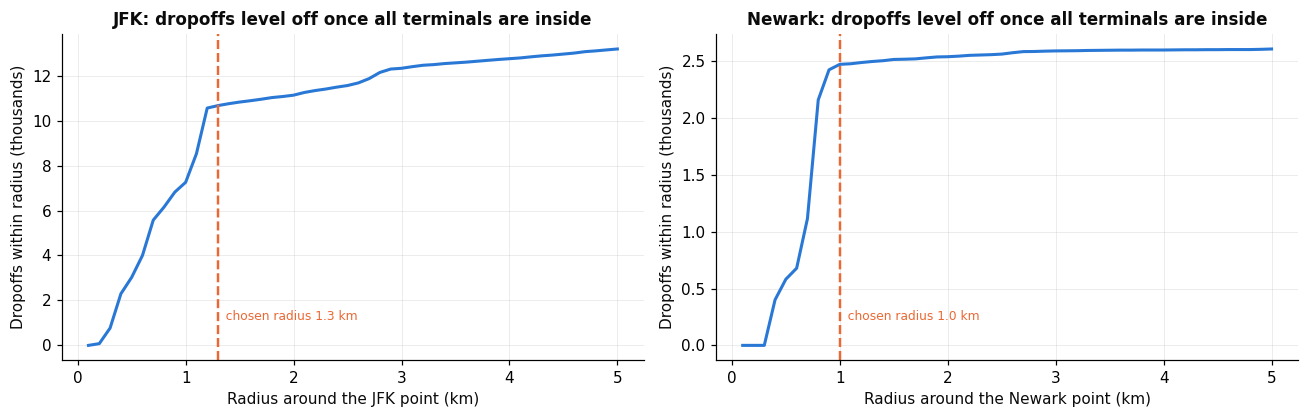

saved q5_airport_radius_choice.png


In [38]:
ESB = (40.756724, -73.983806)
JFK = (40.647929, -73.777813)
EWR = (40.689442, -74.173242)
ESB_R = 0.5

df["d_pick_esb"] = haversine_np(df.pickup_longitude, df.pickup_latitude, ESB[1], ESB[0])
df["d_drop_jfk"] = haversine_np(df.dropoff_longitude, df.dropoff_latitude, JFK[1], JFK[0])
df["d_drop_ewr"] = haversine_np(df.dropoff_longitude, df.dropoff_latitude, EWR[1], EWR[0])
print("straight-line distance ESB -> JFK: %.1f km,  ESB -> Newark: %.1f km"
      % (haversine_np(ESB[1], ESB[0], JFK[1], JFK[0]), haversine_np(ESB[1], ESB[0], EWR[1], EWR[0])))

# Radius motivation 1: dropoffs within r of each airport point (all trips, any origin)
r_grid = np.round(np.arange(0.1, 5.01, 0.1), 2)


def dropoff_curve(col):
    d = np.sort(df[col].values)
    return np.searchsorted(d, r_grid, side="right")


def flat_radius(counts, gain=0.01, steps=3, r_min=0.5):
    # smallest r >= r_min after which each of the next `steps` 100 m steps adds < gain (1%) more dropoffs
    growth = np.diff(counts) / np.maximum(counts[:-1], 1)
    for i in range(len(growth) - steps):
        if r_grid[i] >= r_min and (growth[i:i + steps] < gain).all():
            return float(r_grid[i])
    return float(r_grid[-1])


curves = {"JFK": dropoff_curve("d_drop_jfk"), "Newark": dropoff_curve("d_drop_ewr")}
JFK_R, EWR_R = flat_radius(curves["JFK"]), flat_radius(curves["Newark"])
for name, R in [("JFK", JFK_R), ("Newark", EWR_R)]:
    c = curves[name]
    i = int(np.where(r_grid == R)[0][0])
    print(f"{name}: chosen radius {R} km -> {c[i]:,d} dropoffs; the next 500 m would add only "
          f"{(c[i + 5] / c[i] - 1) * 100:.1f}% more; 2x the radius would add {(c[min(2 * i + 1, len(c) - 1)] / c[i] - 1) * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, chosen, name in [(axes[0], JFK_R, "JFK"), (axes[1], EWR_R, "Newark")]:
    counts = curves[name]
    ax.plot(r_grid, counts / 1000, color=BLUE, lw=2)
    ax.axvline(chosen, color=ORANGE, lw=1.6, ls="--")
    ax.text(chosen, ax.get_ylim()[1] * 0.08, f"  chosen radius {chosen} km", color=ORANGE, fontsize=8)
    ax.set_xlabel(f"Radius around the {name} point (km)")
    ax.set_ylabel("Dropoffs within radius (thousands)")
    ax.set_title(f"{name}: dropoffs level off once all terminals are inside")
fig.tight_layout()
save(fig, "q5_airport_radius_choice.png")

In [39]:
# Radius motivation 2: sensitivity of the result to the ESB radius
rows = []
for r in [0.2, 0.3, 0.5, 0.75]:
    for name, col, R in [("JFK", "d_drop_jfk", JFK_R), ("Newark", "d_drop_ewr", EWR_R)]:
        t = df[(df.d_pick_esb < r) & (df[col] < R)]
        rows.append({"ESB radius (m)": int(r * 1000), "airport": name, "trips": len(t),
                     "median minutes": round(t.duration_min.median(), 1), "mean minutes": round(t.duration_min.mean(), 1)})
esb_sens = pd.DataFrame(rows)
display(esb_sens.pivot(index="ESB radius (m)", columns="airport"))

# Radius motivation 3: sensitivity of the result to the airport radius (ESB radius fixed at ESB_R)
rows = []
for name, col, radii in [("JFK", "d_drop_jfk", [1.0, JFK_R, 2.0, 3.0]), ("Newark", "d_drop_ewr", [0.75, EWR_R, 1.5, 2.0])]:
    for R in sorted(set(radii)):
        t = df[(df.d_pick_esb < ESB_R) & (df[col] < R)]
        rows.append({"airport": name, "airport radius (km)": R, "chosen": R in (JFK_R, EWR_R) and R == (JFK_R if name == "JFK" else EWR_R),
                     "trips": len(t), "median minutes": round(t.duration_min.median(), 1),
                     "mean minutes": round(t.duration_min.mean(), 1)})
ap_sens = pd.DataFrame(rows)
display(ap_sens.set_index(["airport", "airport radius (km)"]))

trips = pd.concat([
    df[(df.d_pick_esb < ESB_R) & (df.d_drop_jfk < JFK_R)].assign(airport="JFK"),
    df[(df.d_pick_esb < ESB_R) & (df.d_drop_ewr < EWR_R)].assign(airport="Newark"),
])
print("trips used:", trips.airport.value_counts().to_dict())

trips        median minutes        mean minutes       
airport          JFK Newark            JFK Newark          JFK Newark
ESB radius (m)                                                       
200              167     53           47.9   33.9         50.3   37.9
300              349     95           45.4   32.9         48.9   36.6
500              838    230           46.1   33.2         49.1   36.4
750             1698    466           46.6   33.9         49.7   36.8

chosen  trips  median minutes  mean minutes
airport airport radius (km)                                             
JFK     1.00                  False    540            45.4          48.3
        1.30                   True    838            46.1          49.1
        2.00                  False    862            46.0          49.1
        3.00                  False    916            46.0          49.1
Newark  0.75                  False    183            33.3          36.8
        1.00                   True    230            33.2          36.4
        1.50                  False    234            33.1          36.3
        2.00                  False    236            33.1          36.3

trips used: {'JFK': 838, 'Newark': 230}


In [40]:
PERIODS = [("Night\n00-06", 0, 6), ("Morning peak\n06-10", 6, 10), ("Midday\n10-15", 10, 15),
           ("Afternoon peak\n15-19", 15, 19), ("Evening\n19-24", 19, 24)]
trips["period"] = pd.cut(trips.hour, [p[1] for p in PERIODS] + [24], right=False, labels=[p[0] for p in PERIODS])


def describe(g):
    return pd.Series({"trips": len(g), "mean_min": g.duration_min.mean(), "median_min": g.duration_min.median(),
                      "q25": g.duration_min.quantile(0.25), "q75": g.duration_min.quantile(0.75),
                      "ci95": 1.96 * g.duration_min.std(ddof=1) / np.sqrt(len(g)) if len(g) > 1 else np.nan,
                      "mean_speed_kmh": g.avg_speed_kmh.mean()})


overall = trips.groupby("airport").apply(describe).round(1)
print("Overall (all hours):")
display(overall)
by_hour = trips.groupby(["airport", "hour"]).apply(describe).round(2)
by_period = trips.groupby(["airport", "period"], observed=False).apply(describe).round(1)
display(by_period.unstack("airport"))

cmp = []
for p, *_ in PERIODS:
    a = trips[(trips.airport == "JFK") & (trips.period == p)].duration_min
    b = trips[(trips.airport == "Newark") & (trips.period == p)].duration_min
    pval = sps.mannwhitneyu(a, b).pvalue if len(a) > 2 and len(b) > 2 else np.nan
    cmp.append({"period": p.replace("\n", " "), "JFK median": round(a.median(), 1), "Newark median": round(b.median(), 1),
                "Newark - JFK (min)": round(b.median() - a.median(), 1), "Mann-Whitney p": round(pval, 4)})
print("Median travel time, Newark compared with JFK:")
display(pd.DataFrame(cmp))
for ap in ["JFK", "Newark"]:
    h = by_hour.loc[ap]
    h = h[h.trips >= 5]
    print(f"{ap}: fastest hour {h.mean_min.idxmin()}:00 ({h.mean_min.min():.0f} min), "
          f"slowest hour {h.mean_min.idxmax()}:00 ({h.mean_min.max():.0f} min)")

MIN_N = 5   # hours with fewer trips than this are ignored for "fastest/slowest hour" and not plotted
cmp_df = pd.DataFrame(cmp)
p_all = sps.mannwhitneyu(trips[trips.airport == "JFK"].duration_min, trips[trips.airport == "Newark"].duration_min).pvalue
lines = ["**Q5 summary (generated from the data):**", "",
         f"* Radii: ESB {int(ESB_R * 1000)} m, JFK {JFK_R} km, Newark {EWR_R} km. "
         f"Trips used: JFK {int(overall.loc['JFK', 'trips'])}, Newark {int(overall.loc['Newark', 'trips'])}."]
for ap in ["JFK", "Newark"]:
    o = overall.loc[ap]
    h = by_hour.loc[ap]
    h = h[h.trips >= MIN_N]
    lines.append(f"* **ESB -> {ap}:** mean {o.mean_min:.1f} min (95% CI +/- {o.ci95:.1f}), median {o.median_min:.1f} min, "
                 f"middle 50% of trips {o.q25:.0f}-{o.q75:.0f} min. Fastest hour **{h.mean_min.idxmin():02d}:00** "
                 f"({h.mean_min.min():.0f} min), slowest hour **{h.mean_min.idxmax():02d}:00** ({h.mean_min.max():.0f} min), "
                 f"i.e. the slowest hour takes {h.mean_min.max() / h.mean_min.min():.1f}x as long as the fastest.")
s_esb = esb_sens.groupby("airport")["median minutes"].agg(lambda x: x.max() - x.min())
s_ap = ap_sens.groupby("airport")["median minutes"].agg(lambda x: x.max() - x.min())
lines.append(f"* Newark minus JFK (overall median): {overall.loc['Newark', 'median_min'] - overall.loc['JFK', 'median_min']:+.1f} min "
             f"(Mann-Whitney p = {p_all:.3g}). By period: " + "; ".join(
                 f"{r.period} {r['Newark - JFK (min)']:+.1f} min (p = {r['Mann-Whitney p']:.3g})" for _, r in cmp_df.iterrows()) + ".")
lines.append(f"* Radius sensitivity: changing the ESB radius between 200 and 750 m moves the median by at most "
             f"{s_esb['JFK']:.1f} min (JFK) and {s_esb['Newark']:.1f} min (Newark); changing the airport radius moves it by at most "
             f"{s_ap['JFK']:.1f} min (JFK) and {s_ap['Newark']:.1f} min (Newark).")
display(Markdown("\n".join(lines)))

Overall (all hours):


,trips,mean_min,median_min,q25,q75,ci95,mean_speed_kmh
airport,,,,,,,
JFK,838.0,49.1,46.1,36.7,60.0,1.1,28.6
Newark,230.0,36.4,33.2,28.3,41.0,1.5,31.7


trips        mean_min        median_min          q25  \
airport                  JFK Newark      JFK Newark        JFK Newark   JFK   
period                                                                        
Night\n00-06            65.0   31.0     28.8   27.2       28.6   27.2  26.5   
Morning peak\n06-10    130.0   44.0     37.6   34.0       35.4   31.8  28.4   
Midday\n10-15          324.0   98.0     49.0   37.2       46.2   33.6  39.2   
Afternoon peak\n15-19  260.0   47.0     61.5   44.0       60.6   42.1  49.3   
Evening\n19-24          59.0   10.0     42.0   32.7       41.5   32.9  36.2   

                               q75        ci95        mean_speed_kmh         
airport               Newark   JFK Newark  JFK Newark            JFK Newark  
period                                                                       
Night\n00-06            25.6  30.0   28.8  0.9    0.9           44.5   39.6  
Morning peak\n06-10     26.8  44.1   38.5  1.9    2.7           36.1   33.2  
Midday\n10-15           29.4  56.8   39.7  1.5    2.6           27.5   31.0  
Afternoon peak\n15-19   36.2  72.4   50.0  1.9    3.3           21.8   25.9  
Evening\n19-24          27.5  45.7   35.9  2.2    4.0           31.0   33.8

Median travel time, Newark compared with JFK:


,period,JFK median,Newark median,Newark - JFK (min),Mann-Whitney p
0,Night 00-06,28.6,27.2,-1.4,0.0228
1,Morning peak 06-10,35.4,31.8,-3.6,0.0555
2,Midday 10-15,46.2,33.6,-12.5,0.0000
3,Afternoon peak 15-19,60.6,42.1,-18.5,0.0000
4,Evening 19-24,41.5,32.9,-8.6,0.0010


JFK: fastest hour 3:00 (28 min), slowest hour 16:00 (65 min)
Newark: fastest hour 4:00 (26 min), slowest hour 16:00 (45 min)


**Q5 summary (generated from the data):**

* Radii: ESB 500 m, JFK 1.3 km, Newark 1.0 km. Trips used: JFK 838, Newark 230.
* **ESB -> JFK:** mean 49.1 min (95% CI +/- 1.1), median 46.1 min, middle 50% of trips 37-60 min. Fastest hour **03:00** (28 min), slowest hour **16:00** (65 min), i.e. the slowest hour takes 2.3x as long as the fastest.
* **ESB -> Newark:** mean 36.4 min (95% CI +/- 1.5), median 33.2 min, middle 50% of trips 28-41 min. Fastest hour **04:00** (26 min), slowest hour **16:00** (45 min), i.e. the slowest hour takes 1.7x as long as the fastest.
* Newark minus JFK (overall median): -12.9 min (Mann-Whitney p = 2.41e-30). By period: Night 00-06 -1.4 min (p = 0.0228); Morning peak 06-10 -3.6 min (p = 0.0555); Midday 10-15 -12.5 min (p = 0); Afternoon peak 15-19 -18.5 min (p = 0); Evening 19-24 -8.6 min (p = 0.001).
* Radius sensitivity: changing the ESB radius between 200 and 750 m moves the median by at most 2.5 min (JFK) and 1.0 min (Newark); changing the airport radius moves it by at most 0.7 min (JFK) and 0.2 min (Newark).

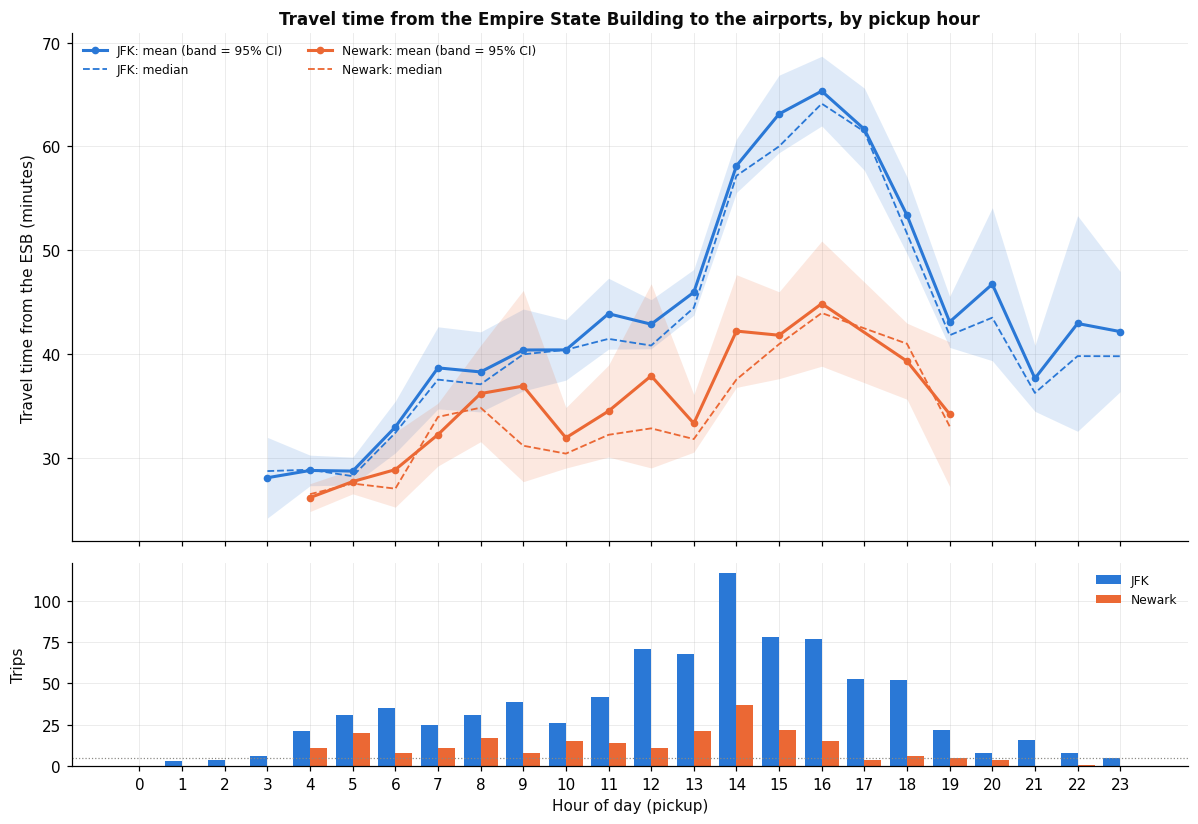

saved q5_travel_time_by_hour.png


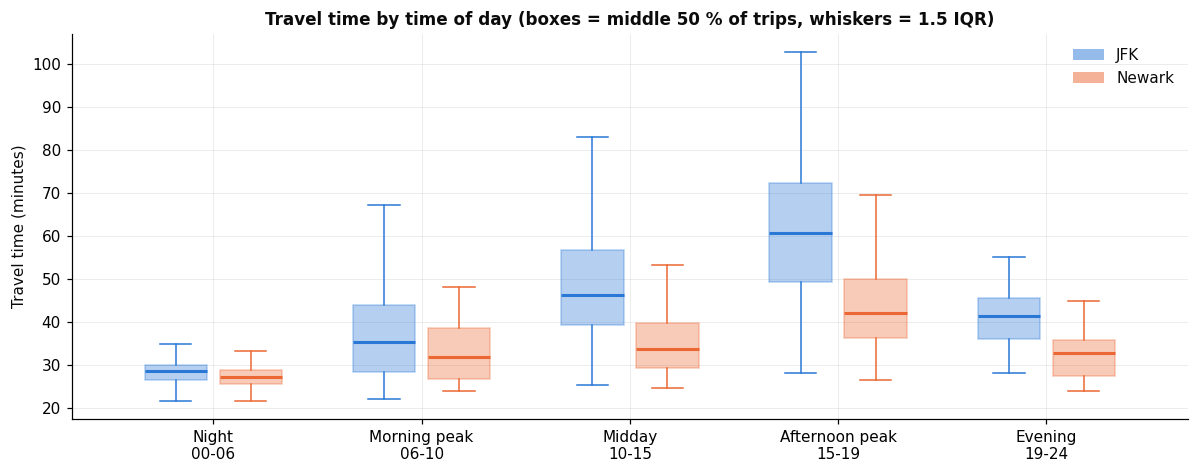

saved q5_travel_time_by_period.png


In [41]:
AP_COL = {"JFK": BLUE, "Newark": ORANGE}
fig, axes = plt.subplots(2, 1, figsize=(11, 7.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
ax = axes[0]
for ap in ["JFK", "Newark"]:
    h = by_hour.loc[ap].reindex(range(24))
    ok = h.trips >= MIN_N
    hh = h[ok]
    ax.fill_between(hh.index, hh.mean_min - hh.ci95, hh.mean_min + hh.ci95, color=AP_COL[ap], alpha=0.15, lw=0)
    ax.plot(hh.index, hh.mean_min, color=AP_COL[ap], lw=2, marker="o", ms=4, label=f"{ap}: mean (band = 95% CI)")
    ax.plot(hh.index, hh.median_min, color=AP_COL[ap], lw=1.2, ls="--", label=f"{ap}: median")
ax.set_ylabel("Travel time from the ESB (minutes)")
ax.set_title("Travel time from the Empire State Building to the airports, by pickup hour")
ax.legend(frameon=False, ncol=2, fontsize=8, loc="upper left")
ax = axes[1]
w = 0.4
for k, ap in enumerate(["JFK", "Newark"]):
    n = by_hour.loc[ap].trips.reindex(range(24), fill_value=0)
    ax.bar(n.index + (k - 0.5) * w, n.values, width=w, color=AP_COL[ap], label=ap)
ax.axhline(MIN_N, color=GREY, lw=0.8, ls=":")
ax.set_ylabel("Trips")
ax.set_xlabel("Hour of day (pickup)")
ax.set_xticks(range(24))
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "q5_travel_time_by_hour.png")

fig, ax = plt.subplots(figsize=(11, 4.4))
labels = [p[0] for p in PERIODS]
for k, ap in enumerate(["JFK", "Newark"]):
    data = [trips[(trips.airport == ap) & (trips.period == p)].duration_min.values for p in labels]
    pos = np.arange(len(labels)) + (k - 0.5) * 0.36
    ax.boxplot(data, positions=pos, widths=0.3, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=AP_COL[ap], alpha=0.35, edgecolor=AP_COL[ap]),
               medianprops=dict(color=AP_COL[ap], lw=2), whiskerprops=dict(color=AP_COL[ap]), capprops=dict(color=AP_COL[ap]))
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_ylabel("Travel time (minutes)")
ax.set_title("Travel time by time of day (boxes = middle 50 % of trips, whiskers = 1.5 IQR)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=AP_COL[a], alpha=0.5) for a in AP_COL], labels=list(AP_COL), frameon=False)
fig.tight_layout()
save(fig, "q5_travel_time_by_period.png")

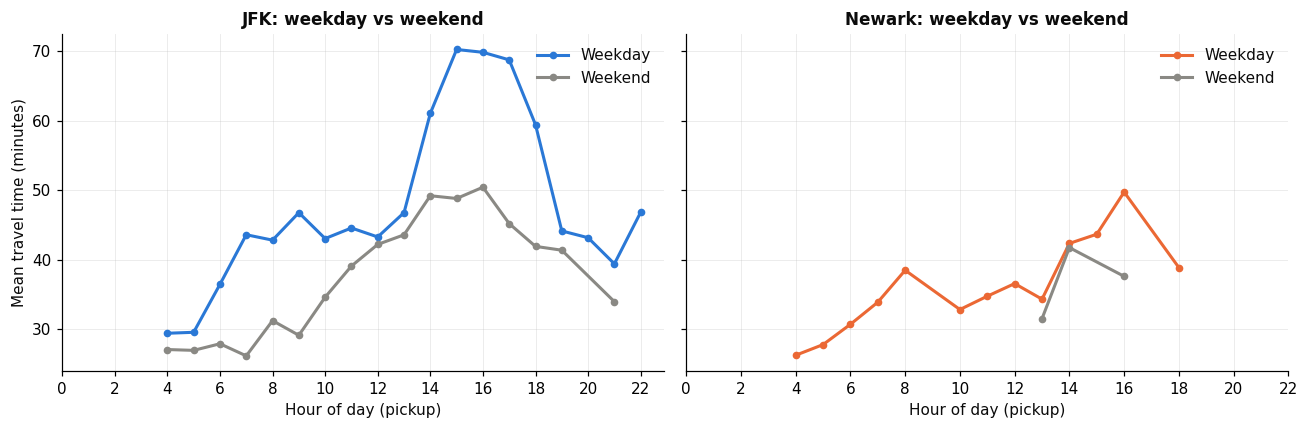

saved q5_weekday_weekend.png


In [42]:
# Does the weekday rush hour matter? Mean JFK travel time by hour, weekdays vs weekends
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, ap in zip(axes, ["JFK", "Newark"]):
    g = trips[trips.airport == ap].groupby(["day_type", "hour"]).duration_min.agg(["mean", "size"])
    for dt_, col in [("Weekday", AP_COL[ap]), ("Weekend", GREY)]:
        s = g.loc[dt_] if dt_ in g.index.get_level_values(0) else None
        if s is None:
            continue
        s = s[s["size"] >= MIN_N]
        ax.plot(s.index, s["mean"], marker="o", ms=4, lw=2, color=col, label=dt_)
    ax.set_title(f"{ap}: weekday vs weekend")
    ax.set_xlabel("Hour of day (pickup)")
    ax.set_xticks(range(0, 24, 2))
    ax.legend(frameon=False)
axes[0].set_ylabel("Mean travel time (minutes)")
fig.tight_layout()
save(fig, "q5_weekday_weekend.png")

### Findings for Question 5

*The exact numbers are in the generated Q5 summary above. Quote those in the report. The points below explain how to read them.*

* **Average travel time.** The summary gives the mean, its 95 % confidence interval and the median for each airport. If the mean is
  above the median, a minority of trips got stuck in heavy traffic and the distribution is right-skewed. In that case the median is
  the better "typical" time.
* **Time of day.** The hourly plot and the fastest/slowest hours in the summary show how strongly the time of day matters. The
  *ratio* of slowest to fastest hour measures how much traffic costs you. Compare the shape with the speed profile in Question 3.5,
  where speeds are highest in the early morning and lowest during the working day. The airport curves should follow the same pattern,
  and the weekday-vs-weekend plot shows whether the peak is a weekday (commuter) effect.
* **JFK vs Newark.** The straight-line distances are similar (printed in the Q5 radius cell), but the routes are very different:
  JFK is reached via the Midtown Tunnel/Long Island Expressway and Van Wyck, Newark via the Lincoln Tunnel and the New Jersey Turnpike.
  The "Newark minus JFK" line in the summary says which airport is faster in each period. The Mann-Whitney p-value says whether that
  difference is larger than chance (p < 0.05).
* **Radius choice.** The radii come from the flattening rule and the dropoff curves. The sensitivity line in the summary shows how much
  the medians move when the radii change. If that is only a minute or two, the conclusions do not depend on the radius.
* **Sample size caveat.** There are far fewer Newark trips. Newark is outside New York City, so yellow-cab trips there cost the
  metered fare plus a surcharge and tolls, and many travellers use the train or a car service. The hourly Newark curve is therefore
  noisier (wider confidence band), and hours with fewer than 5 trips are left out. The 5-period box plot is the more reliable comparison.

In [43]:
import glob
print("Figures saved in this folder:")
for f in sorted(glob.glob("q*.png") + glob.glob("q*.html")):
    print(" ", f)

Figures saved in this folder:
  q1_outliers_before_after.png
  q1_pickup_coordinates_before_after.png
  q2_feature_distributions.png
  q3_1_trips_by_weekday.png
  q3_2_heatmap_day_hour.png
  q3_2_hourly_by_day.png
  q3_3_weekday_vs_weekend_hourly.png
  q3_3_weekday_weekend_stats.png
  q3_4_daily_series.png
  q3_4_holidays_hourly.png
  q3_5_speed_by_hour.png
  q3_5_speed_heatmap.png
  q4_1_heatmap_morning_evening.png
  q4_1_heatmap_weekday_weekend.png
  q4_1_heatmaps.html
  q4_2_dbscan_parameter_sensitivity.png
  q4_2_hotspots.html
  q4_2_hotspots_friday_night.png
  q4_2_hotspots_thursday_evening.png
  q4_2_top_hotspots.png
  q5_airport_radius_choice.png
  q5_travel_time_by_hour.png
  q5_travel_time_by_period.png
  q5_weekday_weekend.png
